# Wind Speed Forecasting with Sequence Models using Keras & TensorFlow
### Filtering, padding & masking · LSTM · GRU · Attention · Transformer · Hyperband tuning

This week we move from *estimating* the current state of the turbine to **forecasting the future**.

We will forecast the **10-min mean wind speed** at turbine **T01** of the EDP wind farm for the **next hour** (6 steps of 10 min), using the **past 6 hours** of SCADA measurements.

<img src="https://i.imgur.com/CjJLXQt.png" alt="Drawing" style="float: left; width: 1500px;" />
<br>
<br>
<br>
<br>
<br>
<br>
<br>
<br>
<br>
<br>
<br>
<br>
<br>
<br>
<br>
<br>
<br>
<br>
<br>


Why bother forecasting wind speed? Remember that

\begin{equation}
Power = \frac{1}{2} \rho C_p A U^3
\end{equation}

The cubic dependence means that a small error in the wind speed forecast $U$ becomes a **much larger** error in power below rated. Good wind forecasts are the foundation of everything that comes after.

We will use a subset of the EDP SCADA series, **Data_TimeSeries.csv**, for this exercise.

***
**Roadmap**

| Part | Topic | What you will learn |
|---|---|---|
| 1 | Data loading & quality | Missing time stamps, continuous time axis |
| 2 | Filtering | Physical/consistency checks, frozen sensors, short vs. long gaps, causal vs. centred smoothing |
| 3 | Sequences, scaling & padding | Sliding windows, padding + `Masking`, the "all features" masking trap |
| 4 | Baseline | **Persistence** – the forecast every model must beat |
| 5 | LSTM & GRU | Recurrent forecasters with multi-step output |
| 6 | Attention | Letting the RNN look back at *all* time steps (and seeing where it looks) |
| 7 | Transformer | Self-attention without recurrence, positional encoding, padding masks |
| 8 | Hyperband | Tuning the GRU – including the look-back window |
| 9 | Comparison | Skill scores, error vs. horizon, example forecasts |

In [21]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print('TensorFlow:', tf.__version__, '| Keras:', keras.__version__)

# make results (more) reproducible - fixed randomness
keras.utils.set_random_seed(42)

# global training settings - reduce EPOCHS if you are short on time
EPOCHS = 20
BATCH_SIZE = 256

TensorFlow: 2.21.0 | Keras: 3.15.1


# Part 1 – Load the data

Let's go pandas - watch for the delimiter (this file is semicolon-separated) and the time zone information.

In [22]:
dataset = pd.read_csv(r"Data/data_exercise_SCADA_analysis_filtering_clustering.csv",
                      delimiter=';',
                      parse_dates=['Timestamp'],
                      index_col='Timestamp')
dataset.head()

,Turbine_ID,Gen_RPM_Max,Gen_RPM_Min,Gen_RPM_Avg,Gen_RPM_Std,Gen_Bear_Temp_Avg,Gen_Phase1_Temp_Avg,Gen_Phase2_Temp_Avg,Gen_Phase3_Temp_Avg,Hyd_Oil_Temp_Avg,...,Grd_Prod_PsbleInd_Max,Grd_Prod_PsbleInd_Min,Grd_Prod_PsbleInd_Std,Grd_Prod_PsbleCap_Avg,Grd_Prod_PsbleCap_Max,Grd_Prod_PsbleCap_Min,Grd_Prod_PsbleCap_Std,Gen_Bear2_Temp_Avg,Nac_Direction_Avg,Status_Flag
Timestamp,,,,,,,,,,,,,,,,,,,,,
2017-01-13 03:40:00+00:00,T01,1262.1,205.9,852.9,474.8,35.0,54,55,55,26,...,0.0,-498.3,110.8,53.1,498.3,0.0,110.8,33,342.6,1
2017-01-13 03:50:00+00:00,T07,1359.1,236.2,769.7,465.0,38.0,60,60,59,29,...,0.0,-604.1,75.6,21.4,604.1,0.0,75.6,39,333.6,1
2017-01-13 04:40:00+00:00,T07,233.1,158.5,203.5,22.7,35.0,46,47,47,30,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,33,326.7,2
2017-01-13 05:00:00+00:00,T07,1250.7,113.7,351.2,388.3,33.0,42,42,42,30,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,31,310.1,2
2017-01-13 05:00:00+00:00,T01,206.4,143.0,158.0,14.5,30.0,36,36,36,26,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,27,311.0,2


### Clear the repetitive 'time zone' information --> '+00:00'
Timestamp is already our index and in `datetime` format, so we can use the `tz_localize` function

In [23]:
dataset.index = dataset.index.tz_localize(None)
dataset.head()

,Turbine_ID,Gen_RPM_Max,Gen_RPM_Min,Gen_RPM_Avg,Gen_RPM_Std,Gen_Bear_Temp_Avg,Gen_Phase1_Temp_Avg,Gen_Phase2_Temp_Avg,Gen_Phase3_Temp_Avg,Hyd_Oil_Temp_Avg,...,Grd_Prod_PsbleInd_Max,Grd_Prod_PsbleInd_Min,Grd_Prod_PsbleInd_Std,Grd_Prod_PsbleCap_Avg,Grd_Prod_PsbleCap_Max,Grd_Prod_PsbleCap_Min,Grd_Prod_PsbleCap_Std,Gen_Bear2_Temp_Avg,Nac_Direction_Avg,Status_Flag
Timestamp,,,,,,,,,,,,,,,,,,,,,
2017-01-13 03:40:00,T01,1262.1,205.9,852.9,474.8,35.0,54,55,55,26,...,0.0,-498.3,110.8,53.1,498.3,0.0,110.8,33,342.6,1
2017-01-13 03:50:00,T07,1359.1,236.2,769.7,465.0,38.0,60,60,59,29,...,0.0,-604.1,75.6,21.4,604.1,0.0,75.6,39,333.6,1
2017-01-13 04:40:00,T07,233.1,158.5,203.5,22.7,35.0,46,47,47,30,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,33,326.7,2
2017-01-13 05:00:00,T07,1250.7,113.7,351.2,388.3,33.0,42,42,42,30,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,31,310.1,2
2017-01-13 05:00:00,T01,206.4,143.0,158.0,14.5,30.0,36,36,36,26,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,27,311.0,2


## Extract data for the turbine in question : T01

We index the dataframe based on the values in the column `Turbine_ID` - and **always sort the index**: the file contains four turbines, and nothing guarantees that the rows of one turbine come in chronological order. A sequence model trained on a shuffled time axis learns nonsense, and it won't throw an error to warn you.

In [24]:
dataset_T01 = dataset[dataset.Turbine_ID == 'T01'].sort_index()
duplicate_count = dataset_T01.index.duplicated().sum()
if duplicate_count:
    dataset_T01 = dataset_T01.groupby(level=0).mean(numeric_only=True)
    print(f'Aggregated {duplicate_count} duplicate timestamp rows by mean.')

print('Is the index sorted?     ', dataset_T01.index.is_monotonic_increasing)
print('Duplicated time stamps:  ', dataset_T01.index.duplicated().sum())
print('Null values:             ', dataset_T01.isnull().sum().sum())
dataset_T01.head()

Aggregated 6 duplicate timestamp rows by mean.
Is the index sorted?      True
Duplicated time stamps:   0
Null values:              2


,Gen_RPM_Max,Gen_RPM_Min,Gen_RPM_Avg,Gen_RPM_Std,Gen_Bear_Temp_Avg,Gen_Phase1_Temp_Avg,Gen_Phase2_Temp_Avg,Gen_Phase3_Temp_Avg,Hyd_Oil_Temp_Avg,Gear_Oil_Temp_Avg,...,Grd_Prod_PsbleInd_Max,Grd_Prod_PsbleInd_Min,Grd_Prod_PsbleInd_Std,Grd_Prod_PsbleCap_Avg,Grd_Prod_PsbleCap_Max,Grd_Prod_PsbleCap_Min,Grd_Prod_PsbleCap_Std,Gen_Bear2_Temp_Avg,Nac_Direction_Avg,Status_Flag
Timestamp,,,,,,,,,,,,,,,,,,,,,
2017-01-01 00:00:00,1460.9,1239.2,1313.7,47.9,36.0,57.0,57.0,57.0,26.0,47.0,...,-621.9,-1000.0,67.1,978.4,1000.0,621.9,67.1,45.0,108.1,0.0
2017-01-01 00:10:00,1410.6,1229.4,1271.3,27.6,36.0,57.0,57.0,57.0,26.0,47.0,...,-477.2,-1000.0,120.9,900.7,1000.0,477.2,120.9,44.0,108.1,0.0
2017-01-01 00:20:00,1444.1,1226.7,1270.4,30.8,36.0,56.0,56.0,56.0,26.0,46.0,...,-291.4,-1000.0,149.3,865.2,1000.0,291.4,149.3,44.0,114.7,0.0
2017-01-01 00:30:00,1300.0,1228.1,1256.1,11.8,36.0,56.0,56.0,56.0,26.0,46.0,...,-222.0,-1000.0,187.8,734.6,1000.0,222.0,187.8,43.0,114.7,0.0
2017-01-01 00:40:00,1294.1,1221.2,1252.9,11.2,36.0,56.0,56.0,56.0,26.0,46.0,...,-54.4,-876.1,174.1,496.5,876.1,54.4,174.1,43.0,114.7,0.0


## 'Real data' has missing time stamps – we should always check

No `NaN`s in the file doesn't mean no missing data: missing periods are simply **rows that do not exist**.

### via explicit listing : `pd.date_range().difference()`

In [25]:
sampling_rate = '10min' # we have 10min resolution in our dataset

missing_time_stamps = pd.date_range(start=dataset_T01.index[0],
                                    end=dataset_T01.index[-1],
                                    freq=sampling_rate).difference(dataset_T01.index)

print('Number of missing time stamps:', len(missing_time_stamps))
print(missing_time_stamps[:10])

Number of missing time stamps: 322
DatetimeIndex(['2017-03-26 02:00:00', '2017-03-26 02:10:00',
               '2017-03-26 02:20:00', '2017-03-26 02:30:00',
               '2017-03-26 02:40:00', '2017-03-26 02:50:00',
               '2017-05-09 08:10:00', '2017-05-09 08:20:00',
               '2017-05-09 08:30:00', '2017-05-09 08:40:00'],
              dtype='datetime64[ns]', freq=None)


### or direct NaN placement : `df.resample(sampling_rate).asfreq()`

For sequence models this is the step that matters: we need a **continuous time axis**, where row $i+1$ is always exactly 10 min after row $i$. Otherwise a "6-hour" input window may secretly span several days.

In [26]:
dataset_T01_cont = dataset_T01.resample(sampling_rate).asfreq()

print('Rows before:', len(dataset_T01), '| rows after:', len(dataset_T01_cont))
dataset_T01_cont.loc[missing_time_stamps].head()

Rows before: 52238 | rows after: 52560


,Gen_RPM_Max,Gen_RPM_Min,Gen_RPM_Avg,Gen_RPM_Std,Gen_Bear_Temp_Avg,Gen_Phase1_Temp_Avg,Gen_Phase2_Temp_Avg,Gen_Phase3_Temp_Avg,Hyd_Oil_Temp_Avg,Gear_Oil_Temp_Avg,...,Grd_Prod_PsbleInd_Max,Grd_Prod_PsbleInd_Min,Grd_Prod_PsbleInd_Std,Grd_Prod_PsbleCap_Avg,Grd_Prod_PsbleCap_Max,Grd_Prod_PsbleCap_Min,Grd_Prod_PsbleCap_Std,Gen_Bear2_Temp_Avg,Nac_Direction_Avg,Status_Flag
2017-03-26 02:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-03-26 02:10:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-03-26 02:20:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-03-26 02:30:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-03-26 02:40:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### How long are the gaps?

The *length* of each gap decides how we treat it later: a 10-min hole and a 12-hour hole are very different problems.

In [27]:
def find_gaps(series):
    """
    List the periods of consecutive NaNs in a series with a continuous time index.
    Returns a DataFrame with start, end, number of missing steps and duration of each gap.
    """
    is_gap = series.isna()
    block = (is_gap != is_gap.shift()).cumsum()        # new block id every time we switch gap <-> data
    gaps = (series.index[is_gap].to_series()
            .groupby(block[is_gap].values)
            .agg(['first', 'last', 'count']))
    gaps.columns = ['start', 'end', 'n_steps']
    gaps['duration'] = gaps['n_steps'] * pd.Timedelta(sampling_rate)
    return gaps.reset_index(drop=True)

gaps = find_gaps(dataset_T01_cont.Amb_WindSpeed_Avg)
gaps

,start,end,n_steps,duration
0,2017-03-26 02:00:00,2017-03-26 02:50:00,6,0 days 01:00:00
1,2017-05-09 08:10:00,2017-05-09 12:50:00,29,0 days 04:50:00
2,2017-06-22 09:20:00,2017-06-22 12:00:00,17,0 days 02:50:00
3,2017-07-05 08:30:00,2017-07-05 20:20:00,72,0 days 12:00:00
4,2017-07-06 08:30:00,2017-07-06 20:30:00,73,0 days 12:10:00
5,2017-07-20 20:30:00,2017-07-21 08:00:00,70,0 days 11:40:00
6,2017-07-31 08:20:00,2017-07-31 08:30:00,2,0 days 00:20:00
7,2017-08-11 13:20:00,2017-08-11 14:30:00,8,0 days 01:20:00
8,2017-08-17 08:40:00,2017-08-17 09:30:00,6,0 days 01:00:00
9,2017-08-17 15:40:00,2017-08-17 16:00:00,3,0 days 00:30:00


### Visualization of the time series can also be very helpful to illustrate the missing data

Let's check the mean wind speed and mark the gaps

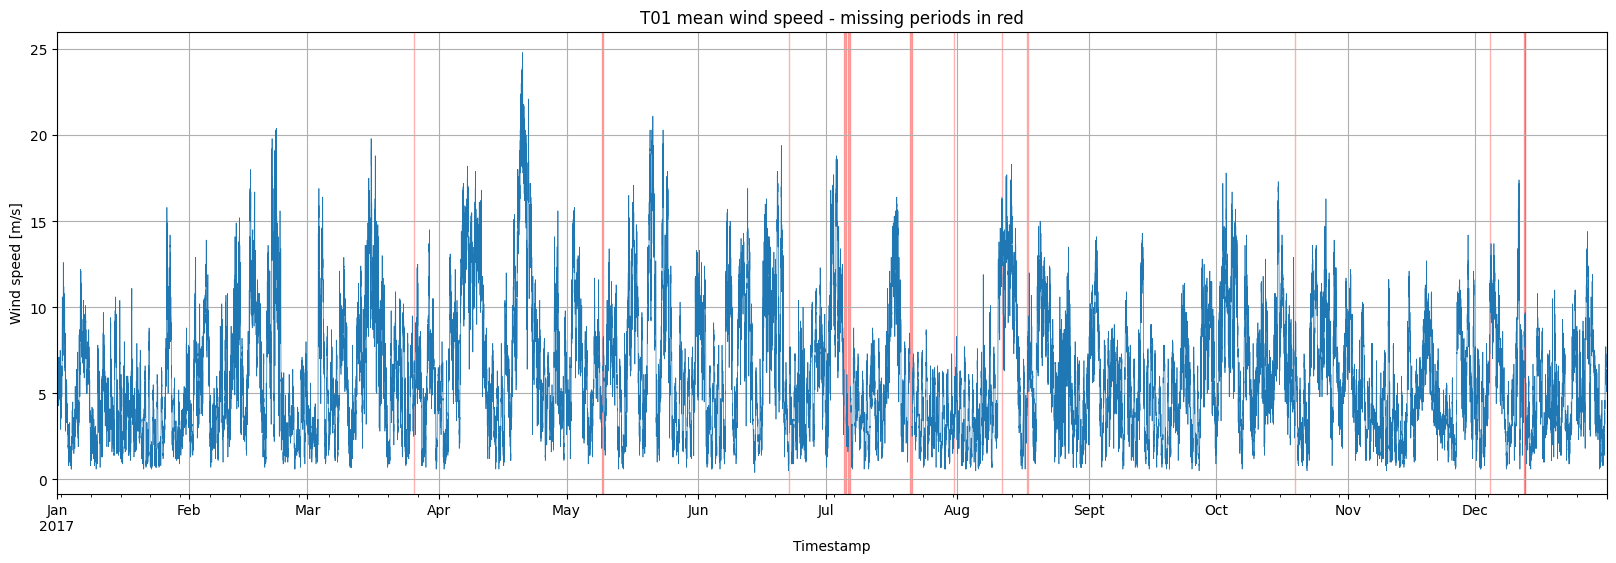

In [28]:
fig, ax = plt.subplots(figsize=(20, 6))
dataset_T01_cont.Amb_WindSpeed_Avg.plot(ax=ax, lw=0.5, grid=True)
for _, gap in gaps.iterrows():
    ax.axvspan(gap.start, gap.end, color='red', alpha=0.3)
ax.set_ylabel('Wind speed [m/s]')
ax.set_title('T01 mean wind speed - missing periods in red')
plt.show()

# Part 2 – Filtering

"Filtering" in time series processing means two different things, and we need both:

1. **Data-quality filtering** – removing values that are *wrong* (sensor errors, impossible values, frozen signals).
2. **Signal filtering (smoothing)** – removing high-frequency content we don't want to model.

We will work only with the wind speed channels from now on.

In [33]:
ws_cols = ['Amb_WindSpeed_Avg', 'Amb_WindSpeed_Std', 'Amb_WindSpeed_Min', 'Amb_WindSpeed_Max']
df = dataset_T01_cont[ws_cols].copy()

## 2.1 Data-quality filtering

| Check | Rule | Why |
|---|---|---|
| Physical range | $0 \le U \le 40$ m/s | Anything outside is a sensor/logging error |
| Internal consistency | $U_{min} \le U_{avg} \le U_{max}$ and $\sigma_U \ge 0$ | The four statistics come from the same 10-min window |
| Frozen sensor | the same value repeated for ≥ 1 hour | Iced or stuck anemometers report a constant value – real wind is never that calm *and* that steady |

Flagged values are set to `NaN`: we would rather have a **known gap** than a **wrong value**.

In [34]:
# 1. physical range
bad_range = (df.Amb_WindSpeed_Avg < 0) | (df.Amb_WindSpeed_Avg > 40)

# 2. internal consistency
bad_consistency = ((df.Amb_WindSpeed_Min > df.Amb_WindSpeed_Avg) |
                   (df.Amb_WindSpeed_Max < df.Amb_WindSpeed_Avg) |
                   (df.Amb_WindSpeed_Std < 0))

# 3. frozen sensor: run of identical consecutive values
stuck_steps = 6                                       # 6 x 10 min = 1 hour
same_as_previous = df.Amb_WindSpeed_Avg.diff().eq(0)
run_id = (~same_as_previous).cumsum()                 # a new run starts whenever the value changes
run_length = same_as_previous.groupby(run_id).transform('sum') + 1
frozen = run_length >= stuck_steps

flagged = bad_range | bad_consistency | frozen
print('Out of physical range:   ', bad_range.sum())
print('Inconsistent statistics: ', bad_consistency.sum())
print('Frozen sensor:           ', frozen.sum())

df.loc[flagged] = np.nan

Out of physical range:    0
Inconsistent statistics:  0
Frozen sensor:            13


This dataset is already fairly clean – Next time it may not be! Two questions to think about:

* At very low wind speeds (and a 0.1 m/s resolution) repeated values are much more plausible. Should the frozen-sensor rule depend on wind speed?
* The anemometer of a turbine sits **behind the rotor** on the nacelle. How might the turbine's operating state affect the measured wind speed?

## 2.2 Short gaps vs. long gaps

We now treat the gaps by their length:

* **Short gaps (≤ 30 min)** → let's fill them. The wind change in shorter periods are a lot less dramatic, and filling keeps more training samples.
* **Long gaps** → leave as `NaN`. These will be **padded and masked** in the network, so the model simply skips them.

**But how do we fill?** Linear interpolation looks nicest, but it uses the value *after* the gap. If a gap sits right at the end of an input window, interpolation sneaks a value from the forecast period into the input – that's **data leakage**: in real operation that value doesn't exist yet.

So we use a **causal** fill (forward-fill) for the **inputs**, and we never fill the **target**: the model should only ever be scored against real measurements.

In [35]:
max_fill = 3   # 3 x 10 min = 30 min

is_gap = df.Amb_WindSpeed_Avg.isna()
gap_id = (is_gap != is_gap.shift()).cumsum()
gap_length = is_gap.groupby(gap_id).transform('sum')
short_gap = is_gap & (gap_length <= max_fill)

# inputs: forward-fill only the short gaps
df_inputs = df.copy()
df_inputs[short_gap] = df.ffill()[short_gap]

# target: filtered, but never filled
target = df.Amb_WindSpeed_Avg.copy()

print('Short gap steps filled (inputs):', short_gap.sum())
print('Remaining missing steps (inputs):', df_inputs.Amb_WindSpeed_Avg.isna().sum())

Short gap steps filled (inputs): 9
Remaining missing steps (inputs): 326


## 2.3 Signal filtering – causal vs. centred smoothing

A rolling mean is a simple low-pass filter: it removes turbulent fluctuations and keeps the trend. Pandas gives you two flavours:

* **trailing (causal)**: `rolling(6).mean()` → uses $t-5 \dots t$
* **centred**: `rolling(6, center=True).mean()` → uses $t-3 \dots t+2$ – **future values!**

Look at the plot below: the centred filter looks "better" because it reacts to changes *before they happen*. Using it on the inputs (or on the target) of a forecasting model is one of the most common ways to get results that are too good to be true.

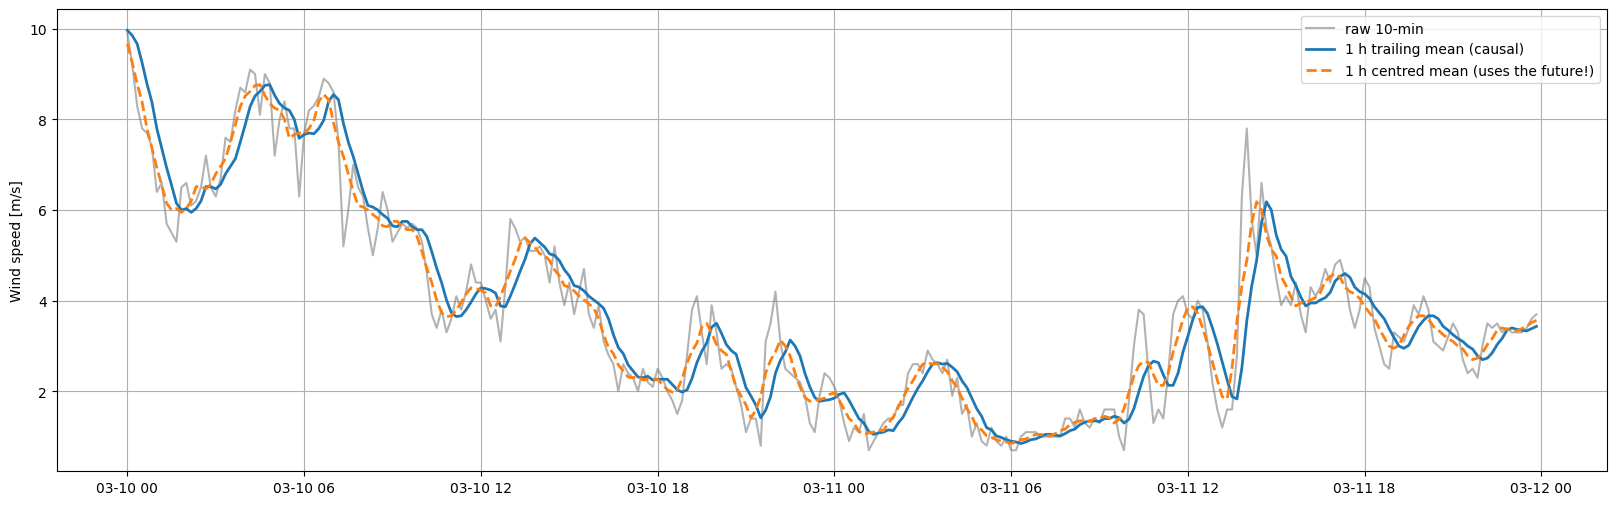

In [36]:
day = slice('2017-03-10', '2017-03-11')
raw = df_inputs.Amb_WindSpeed_Avg.loc[day]

plt.figure(figsize=(20, 6))
plt.plot(raw, label='raw 10-min', color='grey', alpha=0.6)
plt.plot(df_inputs.Amb_WindSpeed_Avg.rolling(6).mean().loc[day], label='1 h trailing mean (causal)', lw=2)
plt.plot(df_inputs.Amb_WindSpeed_Avg.rolling(6, center=True).mean().loc[day], label='1 h centred mean (uses the future!)', lw=2, ls='--')
plt.ylabel('Wind speed [m/s]')
plt.legend()
plt.grid()
plt.show()

We will **not** smooth the target – we want to forecast the real 10-min wind speed. A *trailing* mean could however be a useful extra input feature (try it at home!).

# Part 3 – Define inputs and outputs

***
INPUTS (at each of the past `n_lag` time steps):
   1. Mean wind speed $\rightarrow$ **Amb_WindSpeed_Avg**
   2. Standard deviation of wind speed (indication of turbulence) $\rightarrow$ **Amb_WindSpeed_Std**
   3. Time of day, encoded as $\sin$ and $\cos$ $\rightarrow$ **hour_sin**, **hour_cos**

OUTPUT:
   1. Mean wind speed for the next `n_out` time steps $\rightarrow$ $U(t), U(t+1), \dots, U(t+5)$

Note the change from previous estimators in the class: the target is now **continuous** and **multi-step** – this is a *regression* problem with 6 outputs.

We deliberately keep the turbine's operational channels (power, RPM, pitch) out: wind speed is the meteorological driver. What else could help your *power* forecast is part of (some of) your projects!

### Why $\sin$ and $\cos$ for the time of day?

Wind has a daily (diurnal) cycle. If we feed the hour as a number 0–23, the model thinks 23:50 and 00:00 are far apart. Mapping it onto a circle fixes that:

\begin{equation}
hour_{sin} = \sin\left(\frac{2\pi \cdot hour}{24}\right), \qquad hour_{cos} = \cos\left(\frac{2\pi \cdot hour}{24}\right)
\end{equation}

Why do we need both? Compute $hour_{sin}$ for 04:00 and for 08:00 (in degrees) – what do you notice?

In [37]:
hours = df_inputs.index.hour + df_inputs.index.minute / 60
df_inputs['hour_sin'] = np.sin(2 * np.pi * hours / 24)
df_inputs['hour_cos'] = np.cos(2 * np.pi * hours / 24)

input_ch = ['Amb_WindSpeed_Avg', 'Amb_WindSpeed_Std', 'hour_sin', 'hour_cos']
no_features = len(input_ch)

data = df_inputs[input_ch].copy()
data['target'] = target
data.head()

,Amb_WindSpeed_Avg,Amb_WindSpeed_Std,hour_sin,hour_cos,target
Timestamp,,,,,
2017-01-01 00:00:00,5.6,1.1,0.000000,1.000000,5.6
2017-01-01 00:10:00,4.9,1.0,0.043619,0.999048,4.9
2017-01-01 00:20:00,4.9,1.0,0.087156,0.996195,4.9
2017-01-01 00:30:00,4.5,0.9,0.130526,0.991445,4.5
2017-01-01 00:40:00,4.2,0.9,0.173648,0.984808,4.2


## Divide the time series into sequences

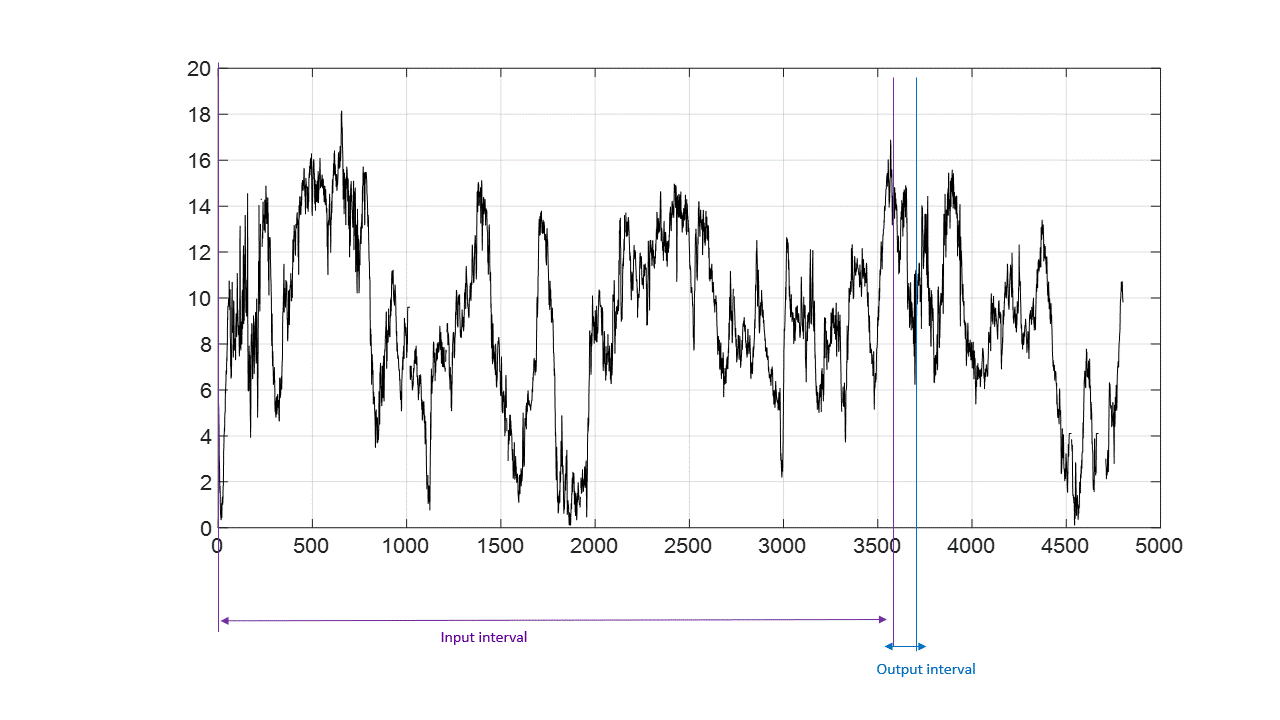

We use two functions to create sequences:

* The **input interval** (`n_lag`) is how far back the network's memory reaches – a *hyperparameter* we can tune later.
* The **output interval** (`n_out`) is the **forecast horizon**. It can be 1 for estimation, no forecast; now it is 6 steps = 1 hour ahead.

In [38]:
### define a function that will prepare the shifting input sequences for the network
def forecast_sequences_input(input_data, n_lag):
    """
    A function that will split the input time series to sequences for nowcast/forecast problems
    Arguments:
        input_data: Time series of input observations as a list, NumPy array or pandas series
        n_lag: number of previous time steps to use for training, a.k.a. time-lag
    Returns:
        Pandas DataFrame of series framed for supervised learning.
    """
    n_vars = input_data.shape[1]
    df = pd.DataFrame(input_data)
    cols, names = list(), list()
    # input sequence (t-n, ... t-1)
    for i in range(n_lag, 0, -1):
        cols.append(df.shift(i))
        names += [('var%d(t-%d)' % (j+1, i)) for j in range(n_vars)]
    # put it all together (aggregate)
    agg = pd.concat(cols, axis=1)
    agg.columns = names
    return agg


### define a function that will prepare the shifting output sequences of the network
def forecast_sequences_output(output_data, n_out):
    """
    A function that will split the output time series to sequences for nowcast/forecast problems
    Arguments:
        output_data: Time series of output observations as a list, NumPy array or pandas series
        n_out: forecast horizon in time steps (for multi-output forecast)
    Returns:
        Pandas DataFrame of series framed for supervised learning.
    """
    n_vars = output_data.shape[1]
    df = pd.DataFrame(output_data)
    cols, names = list(), list()
    # forecast sequence (t, t+1, ... t+n)
    for i in range(0, n_out):
        cols.append(df.shift(-i))
        if i == 0:
            names += [('var%d(t)' % (j+1)) for j in range(n_vars)]
        else:
            names += [('var%d(t+%d)' % (j+1, i)) for j in range(n_vars)]
    # put it all together (aggregate)
    agg = pd.concat(cols, axis=1)
    agg.columns = names
    return agg

### Define length of the input and output intervals within the sequences

In [39]:
n_lag = 36  # number of previous time steps used as input: 36 x 10 min = 6 hours
n_out = 6   # forecast horizon in time steps:              6 x 10 min = 1 hour

### Split into training, validation and test data – in blocks

For time series we **never split at random**: neighbouring 10-min samples are almost identical and consecutive windows overlap almost completely. A random split puts a near-copy of every test sample in the training set, so the test score measures memorisation, not forecasting.

A single chronological cut (e.g. first 60% for training) avoids this, but with only one year of data the test set ends up in a single season – our model would be trained mostly on spring and summer and tested only on early winter.

So we use a **blocked split**:

1. Cut the year into blocks of 14 days.
2. Assign the blocks in a repeating pattern: train, train, train, validation, test → every season appears in all three sets.
3. Build the sequences **inside each block**, so no sequence crosses into another split.
4. Leave a **gap** of one day at the start of every block. Wind is correlated over hours, so without the gap the first test window would still be very similar to the last training window.

Note: this tells us how well the model forecasts *across all seasons*. With several years of data, holding out the last full year would be the cleaner test of "how will it do in the future?".

In [47]:
block_length = pd.Timedelta('14D')
split_pattern = ['train', 'train', 'train', 'validation', 'test']   # 60/20/20, repeated through the year
gap_steps = 144                                                       # 1 day gap at the start of every block

block_id = (data.index - data.index[0]) // block_length              # block number of every time step
blocks = {'train': [], 'validation': [], 'test': []}
for b, block in data.groupby(block_id):
    blocks[split_pattern[b % len(split_pattern)]].append(block)

train_df = pd.concat(blocks['train'])
validation_df = pd.concat(blocks['validation'])
test_df = pd.concat(blocks['test'])

for name, split in [('Train', train_df), ('Validation', validation_df), ('Test', test_df)]:
    months = sorted(split.index.month.unique())
    print(f'{name:<11} {len(split):>6} steps ({len(split)/len(data):.0%}) | months covered: {months}')

Train        32400 steps (62%) | months covered: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
Validation   10080 steps (19%) | months covered: [2, 4, 5, 7, 9, 11, 12]
Test         10080 steps (19%) | months covered: [2, 3, 5, 7, 9, 10, 12]


### Remember to assess if the data split makes sense!

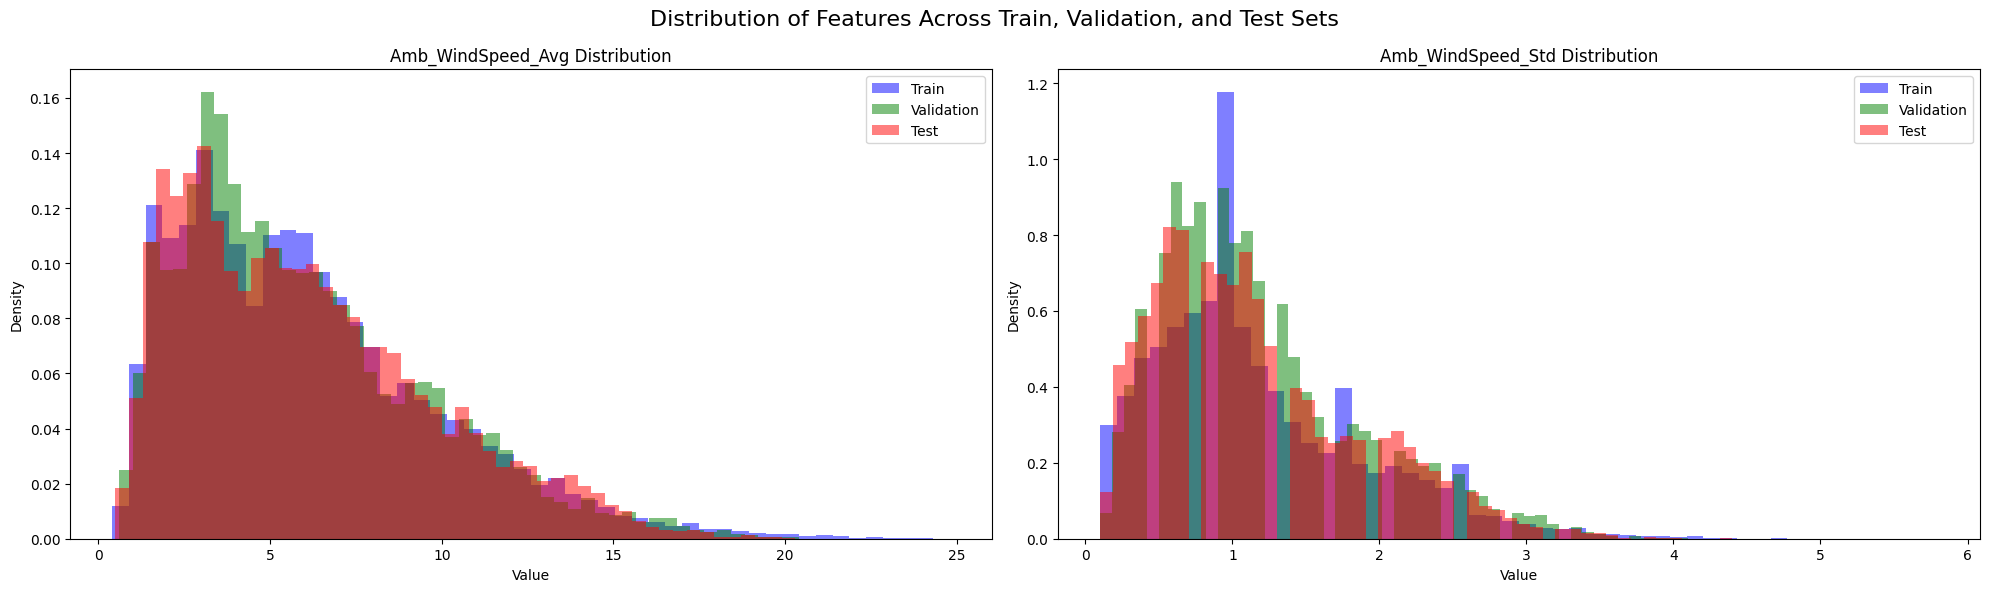

In [41]:
def plot_distributions(train_df, validation_df, test_df, columns):
    fig, axes = plt.subplots(1, len(columns), figsize=(20, 6))
    fig.suptitle('Distribution of Features Across Train, Validation, and Test Sets', fontsize=16)
    colors = ['blue', 'green', 'red']
    datasets = [('Train', train_df), ('Validation', validation_df), ('Test', test_df)]

    for i, column in enumerate(columns):
        for j, (label, split) in enumerate(datasets):
            axes[i].hist(split[column].dropna(), bins=50, alpha=0.5, label=label, color=colors[j], density=True)
        axes[i].set_title(f'{column} Distribution')
        axes[i].set_xlabel('Value')
        axes[i].set_ylabel('Density')
        axes[i].legend()

    plt.tight_layout()
    plt.show()

plot_distributions(train_df, validation_df, test_df, ['Amb_WindSpeed_Avg', 'Amb_WindSpeed_Std'])

### Remember to scale!

Which features do we need to scale for this problem?

* The wind speed channels → yes. We scale **each channel** (not each lag column), fitting **on the training data only**.
* $\sin$/$\cos$ → already in $[-1, 1]$.
* The **target** → yes, with its *own* scaler, so that we can easily convert predictions back to m/s later.

`StandardScaler` simply ignores `NaN`s during fitting and keeps them in place – convenient for our gaps.

In [43]:
from sklearn.preprocessing import StandardScaler

scale_ch = ['Amb_WindSpeed_Avg', 'Amb_WindSpeed_Std']

x_scaler = StandardScaler().fit(train_df[scale_ch])
y_scaler = StandardScaler().fit(train_df[['target']])

def scale(df_split):
    out = df_split.copy()
    out[scale_ch] = x_scaler.transform(df_split[scale_ch])
    out[['target']] = y_scaler.transform(df_split[['target']])
    return out

def inverse_target(y_scaled):
    """Convert scaled target values (any shape) back to m/s."""
    return y_scaler.inverse_transform(y_scaled.reshape(-1, 1)).reshape(y_scaled.shape)


## Build the 3D sequences, filter them and pad the gaps

Recurrent and attention layers in Keras expect inputs shaped `[samples, timesteps, features]`:

- **samples**: the number of sequences (forecast origins)
- **timesteps**: the number of time steps in each sequence → `n_lag`
- **features**: the number of features at each time step → `no_features`

Then, for every sequence:

1. **Drop** it if any of its 6 target values is missing (we can't score it).
2. **Drop** it if more than half of its input window is missing (too little information to forecast from).
3. **Pad** the remaining missing time steps with `pad_value`, to be masked by the network.

### The masking trap
Keras' `Masking` layer only skips a time step if **all** features at that step equal `mask_value`. Our $\sin$/$\cos$ features are computed from the time stamp, so they are *never* missing! If we only replaced the `NaN`s, a missing step would look like `[999, 999, 0.5, 0.87]` and would **not** be masked: the network would happily learn from a wind speed of 999.

So we pad the **whole time step** whenever any feature is missing.

In [44]:
pad_value = 999.0
max_missing_frac = 0.5   # drop sequences with more than 50% missing input steps

def make_sequences(df_scaled):
    """
    Build [samples, n_lag, features] inputs and [samples, n_out] targets from one block of data.
    Returns X, Y and the forecast time stamps (time t of the first forecast step).
    """
    X = forecast_sequences_input(df_scaled[input_ch], n_lag)
    Y = forecast_sequences_output(df_scaled[['target']], n_out)

    X = X.values.reshape((len(X), n_lag, no_features))    # (samples, timesteps, features)
    Y = Y.values

    missing_step = np.isnan(X).any(axis=-1)                # (samples, timesteps): True if ANY feature is missing
    keep = (~np.isnan(Y).any(axis=1)                       # complete target
            & (missing_step.mean(axis=1) <= max_missing_frac))

    X, Y, missing_step = X[keep].copy(), Y[keep], missing_step[keep]
    X[missing_step] = pad_value                            # pad the WHOLE time step

    return X.astype('float32'), Y.astype('float32'), df_scaled.index[keep]


def make_split_sequences(block_list):
    """Build sequences block by block (none crosses a block boundary) and drop those inside the gap."""
    parts = []
    for block in block_list:
        X, Y, times = make_sequences(scale(block))
        keep = times >= block.index[0] + gap_steps * pd.Timedelta(sampling_rate)
        parts.append((X[keep], Y[keep], times[keep]))

    X = np.concatenate([p[0] for p in parts])
    Y = np.concatenate([p[1] for p in parts])
    times = pd.DatetimeIndex(np.concatenate([p[2] for p in parts]))
    return X, Y, times


train_X, train_Y, train_times = make_split_sequences(blocks['train'])
validation_X, validation_Y, validation_times = make_split_sequences(blocks['validation'])
test_X, test_Y, test_times = make_split_sequences(blocks['test'])

print('Training input   (samples, timesteps, features):', train_X.shape)
print('Training output  (samples, horizon):            ', train_Y.shape)
print('Validation input (samples, timesteps, features):', validation_X.shape)
print('Test input       (samples, timesteps, features):', test_X.shape)
print('Sequences containing padded steps (train):      ', (train_X == pad_value).all(axis=-1).any(axis=1).sum())

Training input   (samples, timesteps, features): (29782, 36, 4)
Training output  (samples, horizon):             (29782, 6)
Validation input (samples, timesteps, features): (9133, 36, 4)
Test input       (samples, timesteps, features): (9141, 36, 4)
Sequences containing padded steps (train):       175


# Part 4 – The baseline: persistence

Before building any network, we need to know what "good" means. The simplest forecast in meteorology is **persistence**: *the wind in the next hour will be the same as now*.

\begin{equation}
\hat{U}(t+k) = U(t-1) \qquad k = 0, \dots, 5
\end{equation}

It sounds naive, but for short horizons **persistence is very hard to beat**. A deep learning forecast that does not beat persistence is worthless, no matter how nice the training and validation curves look...

We compare models with the **RMSE-based skill score** relative to persistence:

\begin{equation}
S = 1 - \frac{RMSE_{model}}{RMSE_{persistence}}
\end{equation}

$S > 0$: better than persistence, $S = 0$: equally good, $S < 0$: worse.

In [48]:
# persistence: the forecast for ALL horizons is the last available observation before the forecast starts
#   U_hat(t), U_hat(t+1), ..., U_hat(t+5) = U(t-1)
observed = data['Amb_WindSpeed_Avg']
last_observation = observed.ffill().shift(1)   # value known at time t: the one from t-1 (or earlier, if t-1 is missing)

test_persistence = last_observation.loc[test_times].values                # one value per test forecast (in m/s, not scaled)
test_persistence = np.repeat(test_persistence[:, None], n_out, axis=1)    # same value for all 6 horizons
print('Persistence forecast (samples, horizon):', test_persistence.shape)

# show what persists: when the last observation was made, its value, and the resulting forecast
observation_time = pd.Series(observed.index, index=observed.index).where(observed.notna())
last_observation_time = observation_time.ffill().shift(1)

show = test_times[:5]
table = pd.DataFrame(test_persistence[:5],
                     index=pd.Index(show, name='Forecast starts at t ='),
                     columns=[f'{m} min' for m in 10 * np.arange(1, n_out+1)])
table.insert(0, 'Last observation', last_observation.loc[show].values)
table.insert(0, 'Observed at', last_observation_time.loc[show].dt.strftime('%H:%M').values)
table

Persistence forecast (samples, horizon): (9141, 6)


,Observed at,Last observation,10 min,20 min,30 min,40 min,50 min,60 min
Forecast starts at t =,,,,,,,,
2017-02-27 00:00:00,23:50,2.0,2.0,2.0,2.0,2.0,2.0,2.0
2017-02-27 00:10:00,00:00,2.0,2.0,2.0,2.0,2.0,2.0,2.0
2017-02-27 00:20:00,00:10,1.9,1.9,1.9,1.9,1.9,1.9,1.9
2017-02-27 00:30:00,00:20,2.0,2.0,2.0,2.0,2.0,2.0,2.0
2017-02-27 00:40:00,00:30,1.9,1.9,1.9,1.9,1.9,1.9,1.9


In [49]:
test_Y_ms = inverse_target(test_Y)            # true test targets in m/s
horizon_minutes = 10 * np.arange(1, n_out+1)  # 10, 20, ..., 60 min ahead

def horizon_metrics(y_true, y_pred):
    """RMSE and MAE for each forecast step (columns)."""
    rmse = np.sqrt(np.mean((y_true - y_pred)**2, axis=0))
    mae = np.mean(np.abs(y_true - y_pred), axis=0)
    return rmse, mae

results = {}
rmse, mae = horizon_metrics(test_Y_ms, test_persistence)
results['Persistence'] = {'rmse': rmse, 'mae': mae, 'pred': test_persistence}

pd.DataFrame({'RMSE [m/s]': rmse, 'MAE [m/s]': mae},
             index=pd.Index(horizon_minutes, name='Horizon [min]')).round(3)

,RMSE [m/s],MAE [m/s]
Horizon [min],,
10,0.706,0.506
20,0.970,0.696
30,1.157,0.834
40,1.297,0.941
50,1.427,1.039
60,1.540,1.124


Keep these numbers in mind. With **only local measurements** and a horizon of **one hour**, even a good model typically beats persistence by just a few percent – most of the predictable signal is already contained in "the last value". The skill grows with the horizon and with *more information*: neighbouring sites/turbines, or numerical weather prediction (NWP) for horizons of several hours or days.

We will evaluate every model in the same way, so let's write two small helpers: one for the training history and one for the test evaluation.

In [50]:
def plot_history(history, title=''):
    fig, axes = plt.subplots(1, 2, figsize=(16, 5))
    for ax, metric in zip(axes, ['loss', 'mae']):
        ax.plot(history.history[metric], label='train')
        ax.plot(history.history['val_' + metric], label='validation')
        ax.set_title(f'{title} - {metric}')
        ax.set_xlabel('Epoch')
        ax.legend()
        ax.grid()
    plt.show()


def evaluate_forecast(model, name, X=None):
    """Predict the test set, convert to m/s, store and print the metrics per horizon."""
    X = test_X if X is None else X
    pred = inverse_target(model.predict(X, verbose=0))
    rmse, mae = horizon_metrics(test_Y_ms, pred)
    results[name] = {'rmse': rmse, 'mae': mae, 'pred': pred}

    skill = 1 - rmse / results['Persistence']['rmse']
    table = pd.DataFrame({'RMSE [m/s]': rmse, 'MAE [m/s]': mae, 'Skill vs. persistence': skill},
                         index=pd.Index(horizon_minutes, name='Horizon [min]'))
    print(f'{name}: mean RMSE = {rmse.mean():.3f} m/s, mean skill = {skill.mean():+.1%}')
    return table.round(3)

## LSTM architecture

We first add a Masking layer to tell the network to ignore the padded steps, then two LSTM layers.

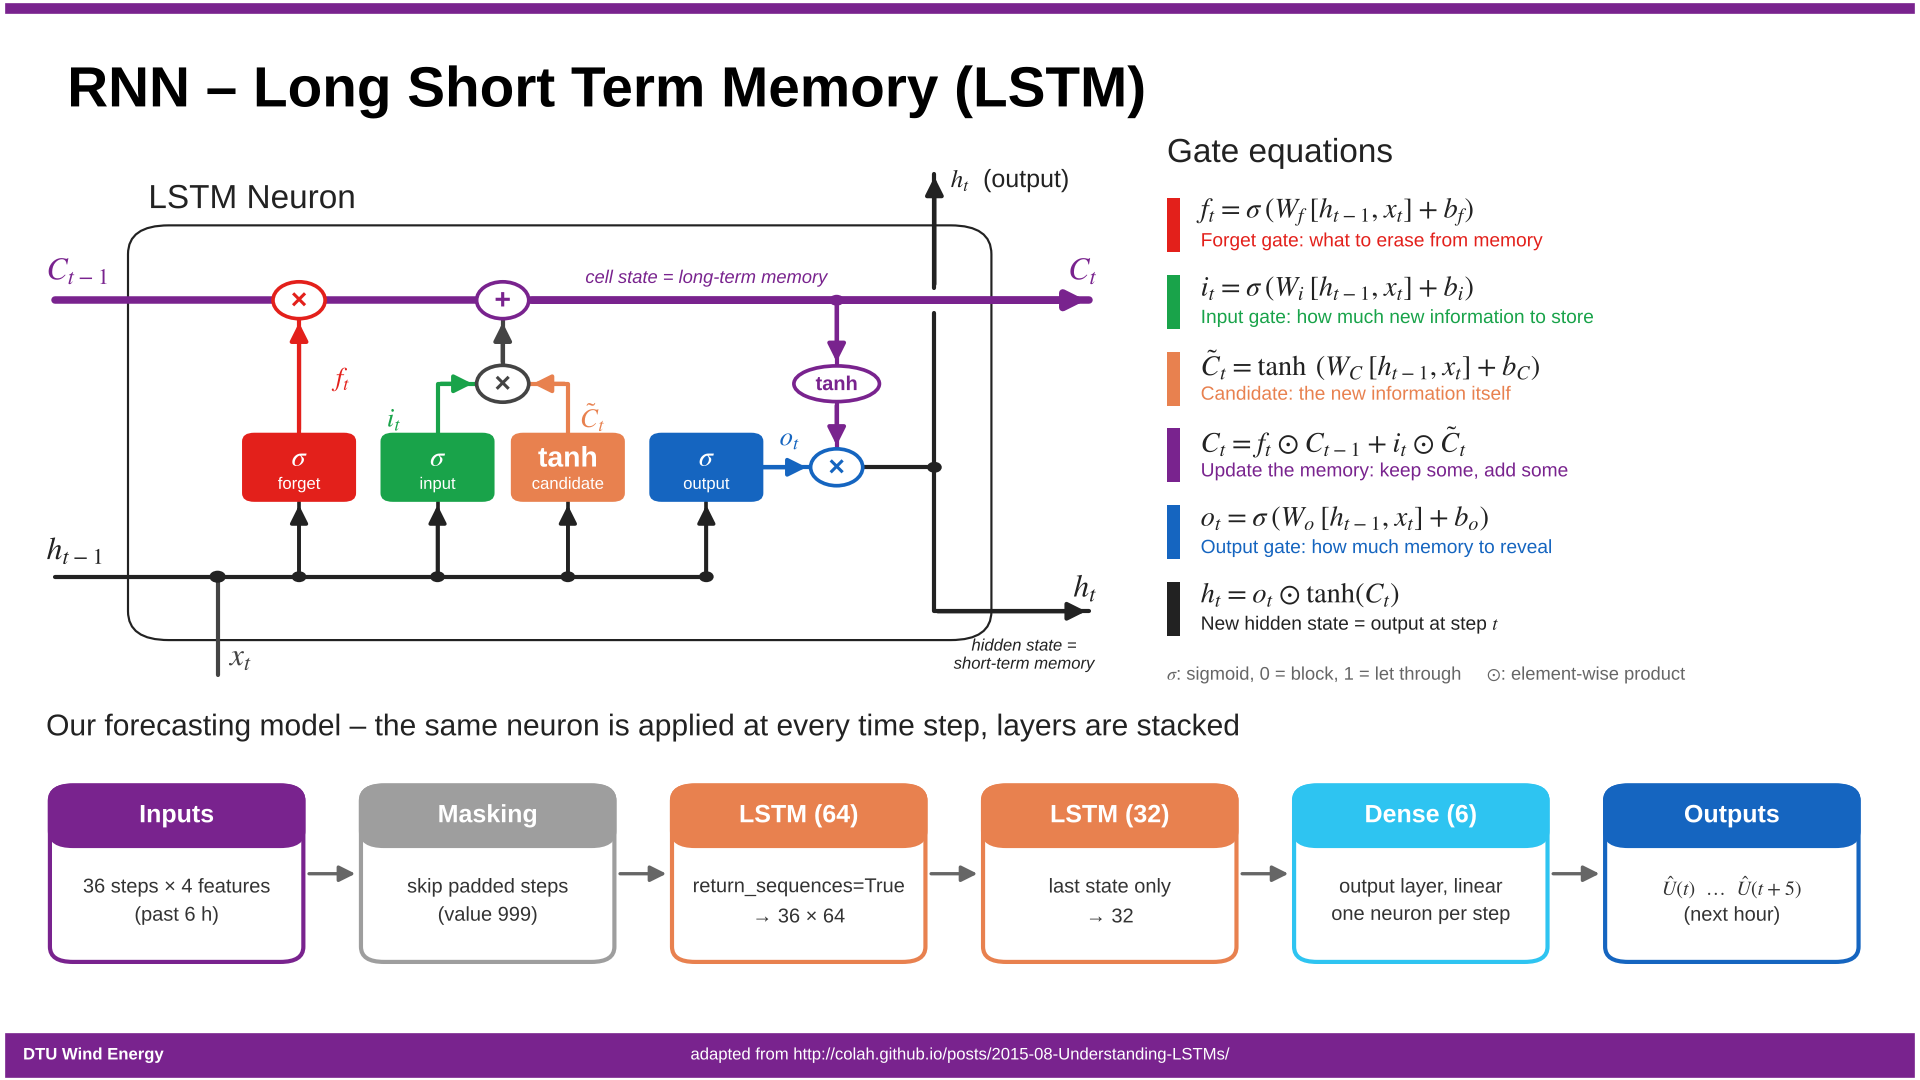

In [51]:
keras.backend.clear_session()

model_lstm = keras.Sequential([
    layers.Input(shape=(n_lag, no_features)),        # (timesteps, features) - samples are handled by batching
    layers.Masking(mask_value=pad_value),            # skip the padded time steps
    layers.LSTM(64, return_sequences=True),          # return_sequences=True -> the next recurrent layer gets the full sequence
    layers.LSTM(32),                                 # last recurrent layer returns only its final state
    layers.Dense(n_out)                              # linear output: one value per forecast step
], name='LSTM')

model_lstm.summary()

Model: "LSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ masking (Masking)               │ (None, 36, 4)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 36, 64)         │        17,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 6)              │           198 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,278 (118.27 KB)

 Trainable params: 30,278 (118.27 KB)

 Non-trainable params: 0 (0.00 B)

### Compile and fit the model

Epoch 1/20
117/117 - 17s - 149ms/step - loss: 0.2443 - mae: 0.3578 - val_loss: 0.1371 - val_mae: 0.2699
Epoch 2/20
117/117 - 11s - 94ms/step - loss: 0.1297 - mae: 0.2690 - val_loss: 0.1192 - val_mae: 0.2511
Epoch 3/20
117/117 - 10s - 88ms/step - loss: 0.1138 - mae: 0.2493 - val_loss: 0.1050 - val_mae: 0.2314
Epoch 4/20
117/117 - 10s - 89ms/step - loss: 0.1038 - mae: 0.2360 - val_loss: 0.0993 - val_mae: 0.2241
Epoch 5/20
117/117 - 11s - 92ms/step - loss: 0.0995 - mae: 0.2299 - val_loss: 0.0975 - val_mae: 0.2207
Epoch 6/20
117/117 - 11s - 96ms/step - loss: 0.0977 - mae: 0.2273 - val_loss: 0.0966 - val_mae: 0.2192
Epoch 7/20
117/117 - 13s - 107ms/step - loss: 0.0969 - mae: 0.2263 - val_loss: 0.0964 - val_mae: 0.2188
Epoch 8/20
117/117 - 15s - 125ms/step - loss: 0.0963 - mae: 0.2256 - val_loss: 0.0967 - val_mae: 0.2196
Epoch 9/20
117/117 - 11s - 91ms/step - loss: 0.0959 - mae: 0.2251 - val_loss: 0.0966 - val_mae: 0.2188
Epoch 10/20
117/117 - 15s - 130ms/step - loss: 0.0955 - mae: 0.2246 - 

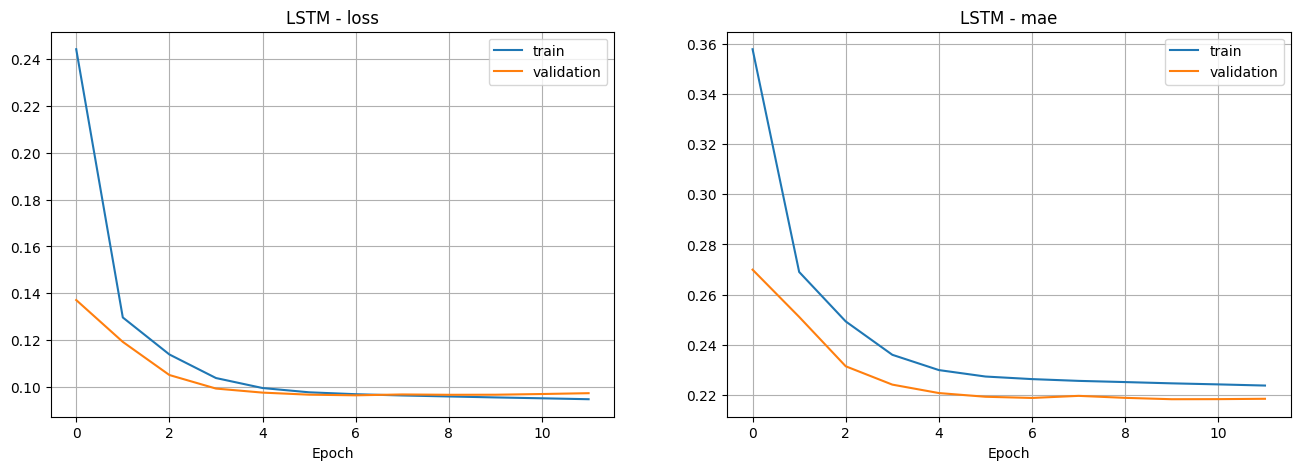

In [52]:
model_lstm.compile(loss='mse', optimizer=keras.optimizers.Adam(learning_rate=1e-3), metrics=['mae'])

es = keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

history = model_lstm.fit(train_X, train_Y,
                         epochs=EPOCHS,
                         batch_size=BATCH_SIZE,
                         validation_data=(validation_X, validation_Y),
                         callbacks=[es],
                         verbose=2)

plot_history(history, 'LSTM')

In [53]:
evaluate_forecast(model_lstm, 'LSTM')

LSTM: mean RMSE = 1.127 m/s, mean skill = +4.3%


,RMSE [m/s],MAE [m/s],Skill vs. persistence
Horizon [min],,,
10,0.692,0.504,0.020
20,0.938,0.684,0.033
30,1.111,0.809,0.039
40,1.246,0.910,0.040
50,1.340,0.986,0.061
60,1.435,1.054,0.068


## If your validation loss is lower than your training loss

This can easily happen here, and it is usually not a bug:

1. **Regularization** – dropout is only active during training.
2. **Different data distributions** – the validation and test periods are not equally "difficult" as the training period. Some seasons are more predictable than others.
3. **Averaging over the epoch** – the training loss is averaged *during* the epoch while the weights are still improving; the validation loss is computed *at the end*.

It is not a problem as long as both losses decrease and the gap does not keep growing.

# Let's try GRUs - Same 3D inputs!

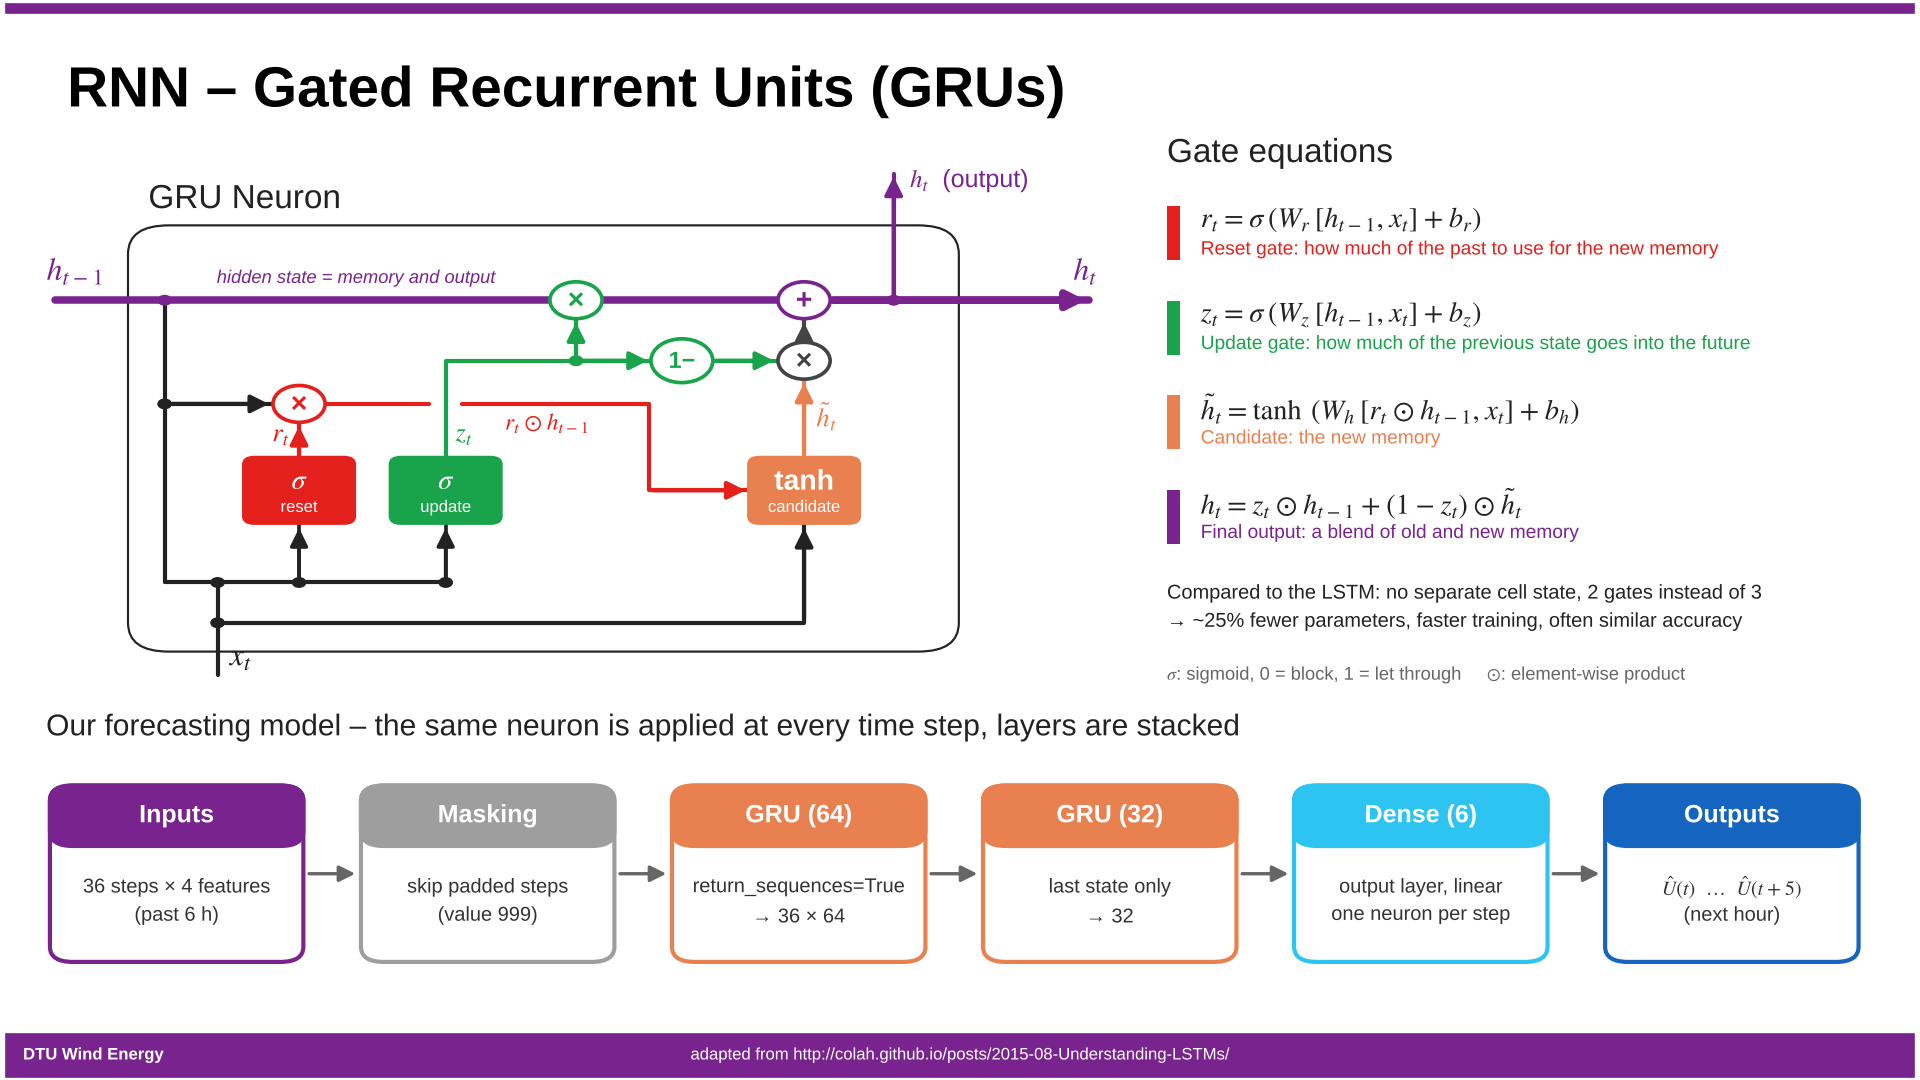

The GRU merges the LSTM's forget and input gates into a single **update gate** and drops the separate cell state. With fewer parameters per unit it trains faster, and on many forecasting problems it performs on par with the LSTM. Check the parameter count in the summary.

Model: "GRU"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ masking (Masking)               │ (None, 36, 4)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ (None, 36, 64)         │        13,440 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_1 (GRU)                     │ (None, 32)             │         9,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 6)              │           198 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,046 (90.02 KB)

 Trainable params: 23,046 (90.02 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
117/117 - 14s - 117ms/step - loss: 0.1840 - mae: 0.3050 - val_loss: 0.1108 - val_mae: 0.2392
Epoch 2/20
117/117 - 9s - 73ms/step - loss: 0.1137 - mae: 0.2449 - val_loss: 0.0993 - val_mae: 0.2235
Epoch 3/20
117/117 - 9s - 73ms/step - loss: 0.1025 - mae: 0.2320 - val_loss: 0.0962 - val_mae: 0.2197
Epoch 4/20
117/117 - 8s - 72ms/step - loss: 0.0994 - mae: 0.2286 - val_loss: 0.0957 - val_mae: 0.2188
Epoch 5/20
117/117 - 8s - 70ms/step - loss: 0.0984 - mae: 0.2273 - val_loss: 0.0954 - val_mae: 0.2184
Epoch 6/20
117/117 - 9s - 75ms/step - loss: 0.0978 - mae: 0.2267 - val_loss: 0.0953 - val_mae: 0.2182
Epoch 7/20
117/117 - 9s - 73ms/step - loss: 0.0974 - mae: 0.2263 - val_loss: 0.0953 - val_mae: 0.2182
Epoch 8/20
117/117 - 9s - 73ms/step - loss: 0.0971 - mae: 0.2259 - val_loss: 0.0953 - val_mae: 0.2181
Epoch 9/20
117/117 - 9s - 77ms/step - loss: 0.0968 - mae: 0.2256 - val_loss: 0.0952 - val_mae: 0.2180
Epoch 10/20
117/117 - 9s - 74ms/step - loss: 0.0966 - mae: 0.2254 - val_loss: 0.

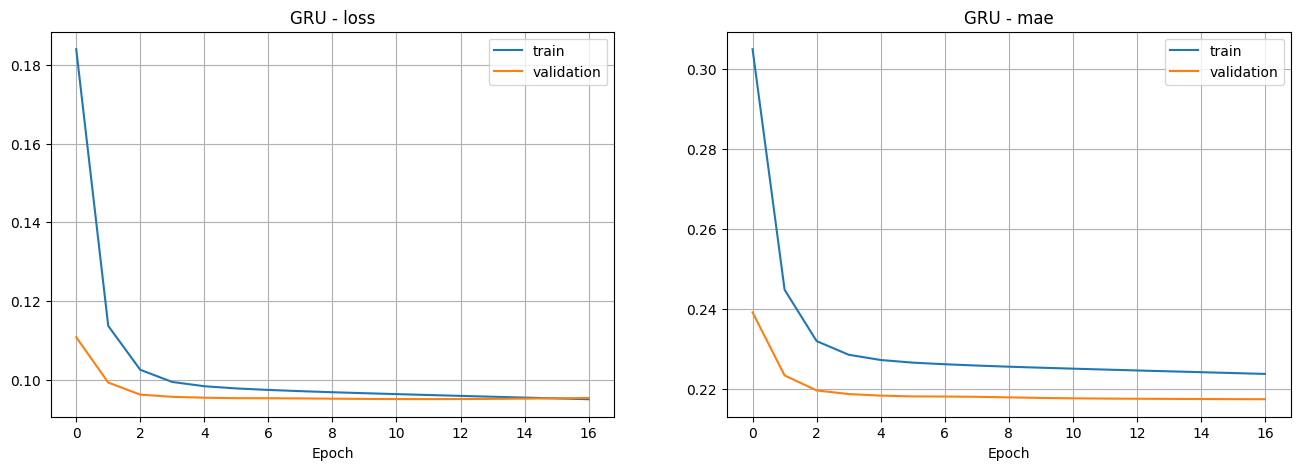

GRU: mean RMSE = 1.123 m/s, mean skill = +4.8%


,RMSE [m/s],MAE [m/s],Skill vs. persistence
Horizon [min],,,
10,0.686,0.496,0.028
20,0.938,0.679,0.033
30,1.105,0.804,0.045
40,1.237,0.903,0.047
50,1.339,0.987,0.061
60,1.430,1.055,0.071


In [54]:
keras.backend.clear_session()

model_gru = keras.Sequential([
    layers.Input(shape=(n_lag, no_features)),
    layers.Masking(mask_value=pad_value),
    layers.GRU(64, return_sequences=True),
    layers.GRU(32),
    layers.Dense(n_out)
], name='GRU')

model_gru.summary()
model_gru.compile(loss='mse', optimizer=keras.optimizers.Adam(learning_rate=1e-3), metrics=['mae'])

history = model_gru.fit(train_X, train_Y,
                        epochs=EPOCHS,
                        batch_size=BATCH_SIZE,
                        validation_data=(validation_X, validation_Y),
                        callbacks=[es],
                        verbose=2)

plot_history(history, 'GRU')
evaluate_forecast(model_gru, 'GRU')

Looks like our forecasts get better over longer horizons over persistence (more than 6% better) - is that to be expected?

# Part 6 – Attention: letting the network look back

The recurrent networks above squeeze the whole 6-hour history into **one final hidden state** before predicting. Everything the model knows about the past must fit through this *bottleneck*.

**Attention** removes the bottleneck. We keep *all* hidden states of the GRU, $h_1, \dots, h_T$, and let the network decide which ones matter for the forecast, using the final state $s = h_T$ as the "question" (the **query**):

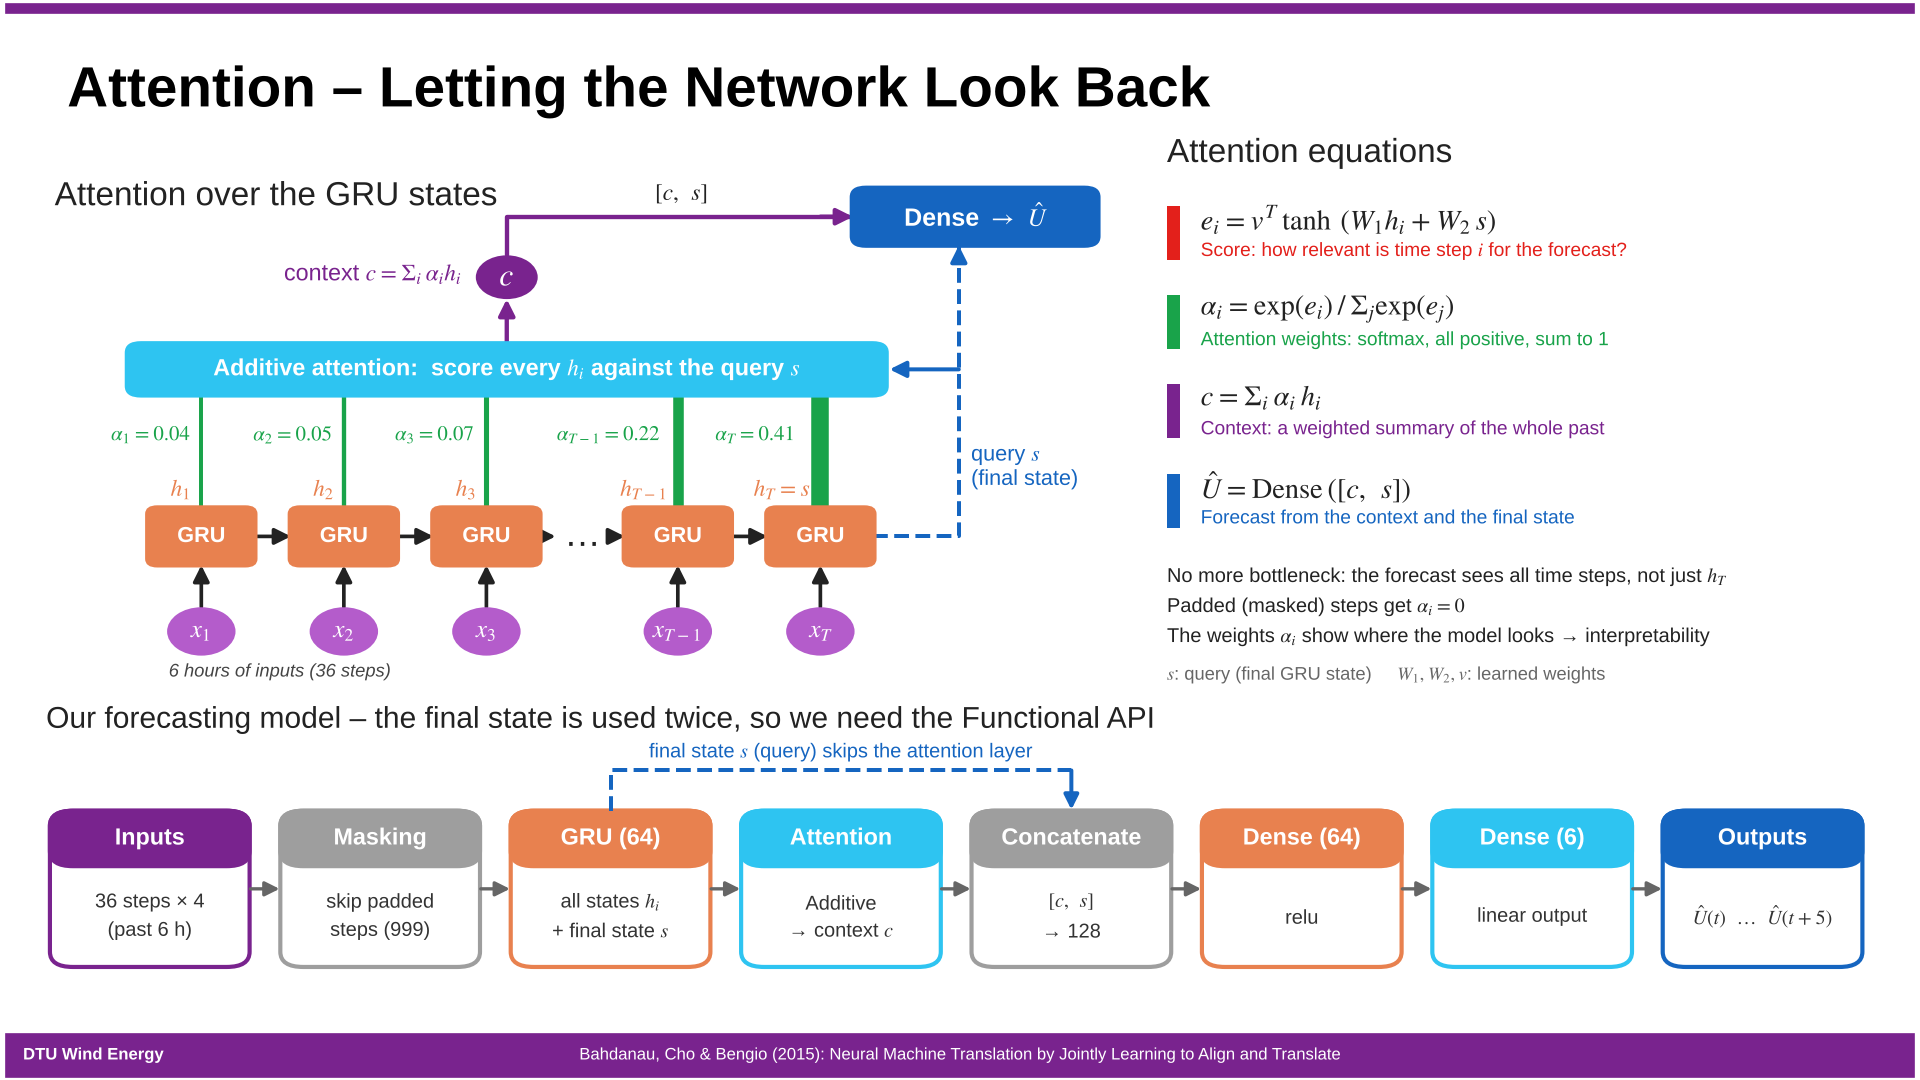

\begin{align}
e_i &= v^\top \tanh\left(W_1 h_i + W_2 s\right) && \text{score: how relevant is time step } i \text{?}\\
\alpha_i &= \frac{\exp(e_i)}{\sum_j \exp(e_j)} && \text{attention weights, } \textstyle\sum_i \alpha_i = 1\\
c &= \sum_i \alpha_i \, h_i && \text{context vector: weighted summary of the past}
\end{align}

The forecast is then made from the context *and* the final state together, $\hat{U} = \text{Dense}([c, s])$.

The $\alpha_i$ in the figure are only an example (the line widths show the weights). We will look at the weights *our* model actually learns after training.

This is **additive (Bahdanau) attention**, available in Keras as `layers.AdditiveAttention`. A bonus: the weights $\alpha_i$ tell us **where the model is looking** – a bit of interpretability in deep learning (very rare!).

Masked time steps automatically get $\alpha_i = 0$, since the mask from the `Masking` layer flows through the GRU into the attention layer.

### The Functional API
A `Sequential` model is a single chain of layers. Here the GRU output is used *twice* – the sequence of all states goes into the attention layer, and the final state $s$ is used both as the query and again in the `Concatenate` layer (the dashed line in the bottom row of the figure). That's no longer a chain, so we need Keras' **Functional API**: we call the layers on tensors and connect them ourselves.

In [55]:
keras.backend.clear_session()

units = 64
inputs = keras.Input(shape=(n_lag, no_features))
x = layers.Masking(mask_value=pad_value)(inputs)

# encoder: keep ALL hidden states (sequence) AND the final state
encoder_seq, encoder_state = layers.GRU(units, return_sequences=True, return_state=True)(x)

# query = final state, reshaped to a sequence of length 1: (batch, 1, units)
query = layers.Reshape((1, units))(encoder_state)

# attention over the encoder states
context, attention_scores = layers.AdditiveAttention(name='bahdanau_attention')(
    [query, encoder_seq], return_attention_scores=True)

# combine the context with the final state and decode to the forecast
x = layers.Concatenate()([context, query])
x = layers.Flatten()(x)
x = layers.Dense(64, activation='relu')(x)
outputs = layers.Dense(n_out)(x)

model_attn = keras.Model(inputs, outputs, name='GRU_Attention')

# a second model sharing the same layers, to read out the attention weights later
attention_viewer = keras.Model(inputs, attention_scores)

model_attn.summary()

Model: "GRU_Attention"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 36, 4)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 36, 4)     │          0 │ input_layer[0][0] │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ masking (Masking)   │ (None, 36, 4)     │          0 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ any (Any)           │ (None, 36)        │          0 │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gru (GRU)           │ [(None, 36, 64),  │     13,440 │ masking[0][0],    │
│                     │ (None, 64)]       │            │ any[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 1, 64)     │          0 │ gru[0][1]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bahdanau_attention  │ [(None, 1, 64),   │         64 │ reshape[0][0],    │
│ (AdditiveAttention) │ (None, 1, 36)]    │            │ gru[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 1, 128)    │          0 │ bahdanau_attenti… │
│ (Concatenate)       │                   │            │ reshape[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 128)       │          0 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 64)        │      8,256 │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 6)         │        390 │ dense[0][0]       │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 22,150 (86.52 KB)

 Trainable params: 22,150 (86.52 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
117/117 - 10s - 86ms/step - loss: 0.1842 - mae: 0.3101 - val_loss: 0.1032 - val_mae: 0.2307
Epoch 2/20
117/117 - 7s - 62ms/step - loss: 0.1045 - mae: 0.2351 - val_loss: 0.0974 - val_mae: 0.2219
Epoch 3/20
117/117 - 7s - 59ms/step - loss: 0.1005 - mae: 0.2298 - val_loss: 0.0957 - val_mae: 0.2194
Epoch 4/20
117/117 - 7s - 56ms/step - loss: 0.0987 - mae: 0.2275 - val_loss: 0.0952 - val_mae: 0.2186
Epoch 5/20
117/117 - 6s - 53ms/step - loss: 0.0977 - mae: 0.2263 - val_loss: 0.0951 - val_mae: 0.2182
Epoch 6/20
117/117 - 8s - 66ms/step - loss: 0.0972 - mae: 0.2257 - val_loss: 0.0952 - val_mae: 0.2182
Epoch 7/20
117/117 - 7s - 63ms/step - loss: 0.0968 - mae: 0.2253 - val_loss: 0.0953 - val_mae: 0.2182
Epoch 8/20
117/117 - 7s - 61ms/step - loss: 0.0965 - mae: 0.2250 - val_loss: 0.0953 - val_mae: 0.2182
Epoch 9/20
117/117 - 6s - 52ms/step - loss: 0.0962 - mae: 0.2248 - val_loss: 0.0954 - val_mae: 0.2182
Epoch 10/20
117/117 - 6s - 52ms/step - loss: 0.0959 - mae: 0.2245 - val_loss: 0.0

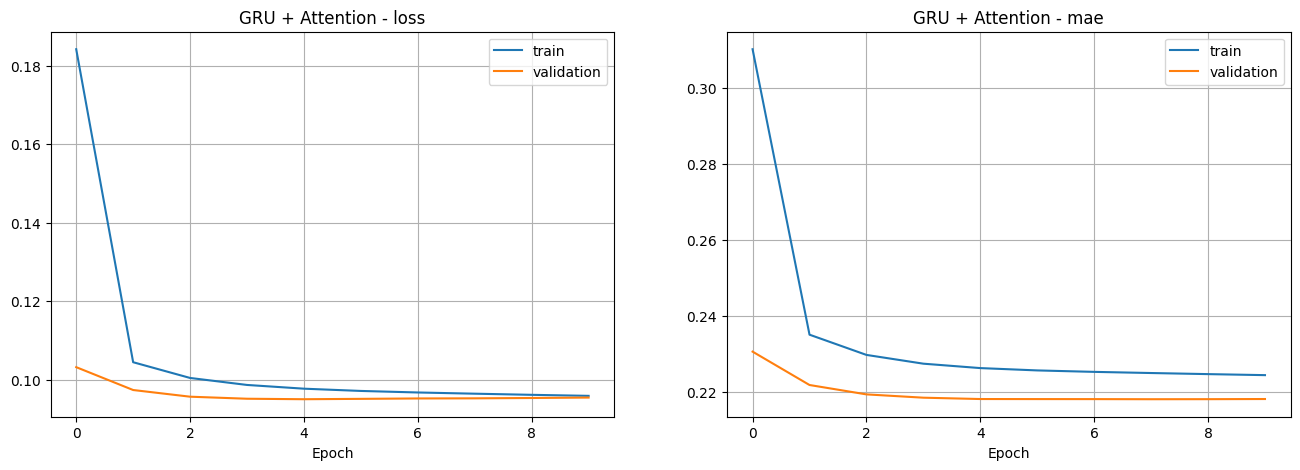

GRU + Attention: mean RMSE = 1.124 m/s, mean skill = +4.5%


,RMSE [m/s],MAE [m/s],Skill vs. persistence
Horizon [min],,,
10,0.698,0.505,0.012
20,0.936,0.679,0.035
30,1.112,0.808,0.039
40,1.234,0.902,0.049
50,1.337,0.986,0.063
60,1.425,1.049,0.075


In [56]:
model_attn.compile(loss='mse', optimizer=keras.optimizers.Adam(learning_rate=1e-3), metrics=['mae'])

history = model_attn.fit(train_X, train_Y,
                         epochs=EPOCHS,
                         batch_size=BATCH_SIZE,
                         validation_data=(validation_X, validation_Y),
                         callbacks=[es],
                         verbose=2)

plot_history(history, 'GRU + Attention')
evaluate_forecast(model_attn, 'GRU + Attention')

### Where does the model look?

The attention weights have the shape `(samples, 1, n_lag)`: for every forecast, one weight per past time step.

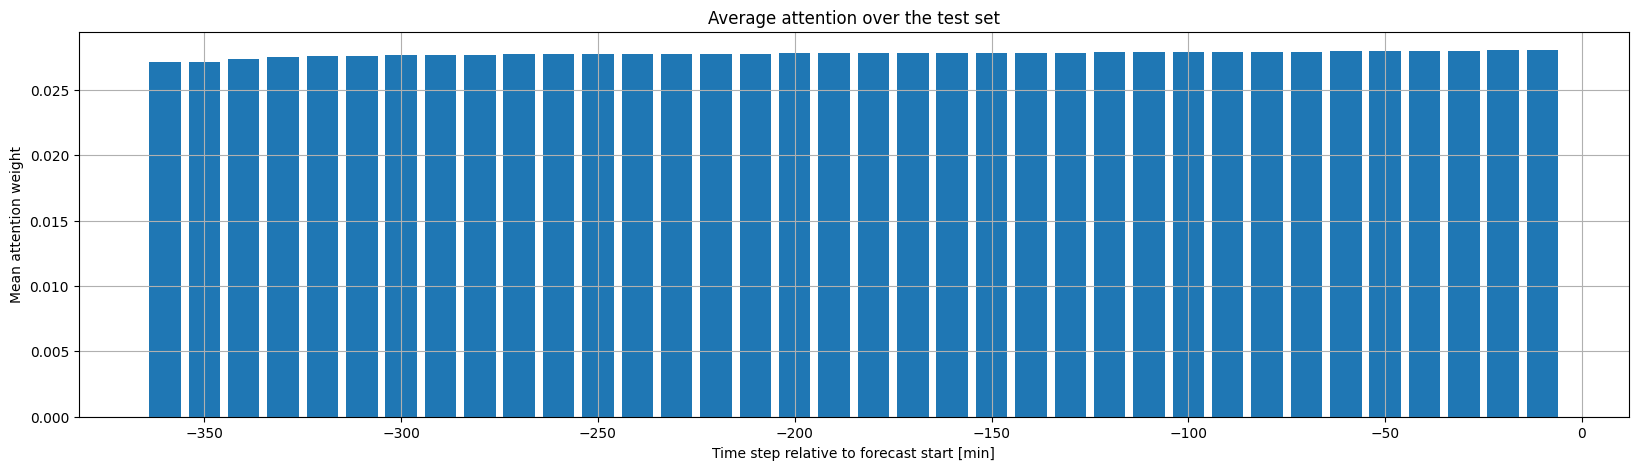

In [57]:
weights = attention_viewer.predict(test_X, verbose=0)[:, 0, :]     # (samples, n_lag)
lag_minutes = -10 * np.arange(n_lag, 0, -1)                         # -360 ... -10 min

fig, axes = plt.subplots(1, 1, figsize=(20, 5))
axes.bar(lag_minutes, weights.mean(axis=0), width=8)
axes.set_xlabel('Time step relative to forecast start [min]')
axes.set_ylabel('Mean attention weight')
axes.set_title('Average attention over the test set')
axes.grid()


Let's discuss:
* Which time steps get the most attention? Does that match your intuition about persistence?
* Is the attention spread out or sharp? Does it change between samples, and what could the model be "looking for" in the older steps?

# Part 7 – THE BEST MODEL: Hyperparameter tuning of the GRU

We tune the **GRU**: it's the cheapest of our models to train (so we can afford many trials) and typically among the strongest here. To find the optimal hyperparameters we again use **Keras Tuner**.

**Tuning process:**

1. **Define Search Space**
   - Specify ranges for hyperparameters (e.g., number of layers, units per layer, dropout, learning rate)
<br>

2. **Train Multiple Models**
   - Keras Tuner automatically trains models with different hyperparameter combinations
<br>

3. **Evaluate Performance**
   - Assess each model's performance based on a **validation** metric
<br>

4. **Select Best Model**
   - Identify the best configuration, retrain it and evaluate it on the test set

### Tuning the look-back window
Earlier we said that the input interval `n_lag` is a hyperparameter too – now we tune it. We built our sequences with 36 steps; a model with a look-back of 12 steps simply uses the **last 12** of them. To do this we write a small `HyperModel` class:

* `build(hp)` creates the framework on what we would like to tune. The input shape is `(None, features)` so that the same architecture accepts any sequence length.
* `fit(hp, model, x, y, ...)` cuts the input windows to the chosen look-back before training.

### 1. Define Search Space

In [58]:
!pip install tensorflow keras-tuner


   ---------------------------------------- 0/2 [kt-legacy]
   ---------------------------------------- 0/2 [kt-legacy]
   ---------------------------------------- 0/2 [kt-legacy]
   -------------------- ------------------- 1/2 [keras-tuner]
   -------------------- ------------------- 1/2 [keras-tuner]
   -------------------- ------------------- 1/2 [keras-tuner]
   -------------------- ------------------- 1/2 [keras-tuner]
   -------------------- ------------------- 1/2 [keras-tuner]
   -------------------- ------------------- 1/2 [keras-tuner]
   -------------------- ------------------- 1/2 [keras-tuner]
   -------------------- ------------------- 1/2 [keras-tuner]
   -------------------- ------------------- 1/2 [keras-tuner]
   -------------------- ------------------- 1/2 [keras-tuner]
   -------------------- ------------------- 1/2 [keras-tuner]
   -------------------- ------------------- 1/2 [keras-tuner]
   -------------------- ------------------- 1/2 [keras-tuner]
   ----------


[notice] A new release of pip is available: 26.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [59]:
import keras_tuner as kt

class GRUForecastHyperModel(kt.HyperModel):

    def build(self, hp):
        model = keras.Sequential(name='GRU_tuned')
        model.add(layers.Input(shape=(None, no_features)))       # None -> any look-back length
        model.add(layers.Masking(mask_value=pad_value))

        n_layers = hp.Int('n_layers', min_value=1, max_value=2)
        dropout = hp.Choice('dropout', [0.0, 0.2])
        for i in range(n_layers):
            model.add(layers.GRU(units=hp.Choice(f'units_{i+1}', [32, 64, 96]),
                                 return_sequences=(i < n_layers - 1)))   # only the last GRU returns a single vector
            model.add(layers.Dropout(dropout))

        model.add(layers.Dense(n_out))

        model.compile(optimizer=keras.optimizers.Adam(
                          learning_rate=1e-3),
                      loss='mse',
                      metrics=['mae'])
        return model

    def fit(self, hp, model, x, y, validation_data=None, **kwargs):
        lookback = hp.Choice('lookback', [12, 24, 36])            # 2, 4 or 6 hours
        x = x[:, -lookback:, :]
        if validation_data is not None:
            x_val, y_val = validation_data
            validation_data = (x_val[:, -lookback:, :], y_val)
        return model.fit(x, y, validation_data=validation_data, **kwargs)

#### Choose the tuner for the hyperparameter search

Keras Tuner offers different strategies for hyperparameter optimization:

1. `GridSearch`: tries **every** combination. Our space has many combinations – this explodes quickly.
2. `RandomSearch`: samples hyperparameters randomly from the search space.
3. `BayesianOptimization`: uses the results so far to pick the next promising configuration.
4. `Hyperband`: an adaptive resource allocation algorithm that dynamically allocates resources to promising configurations.

We will use `Hyperband`, because:

- It's more efficient than grid or random search for larger search spaces
- It finds good configurations quickly by adaptively allocating resources
- It's particularly effective for deep learning models with longer training times

`Hyperband` works by:
- Initially evaluating many configurations with a small number of epochs
- Progressively increasing the epochs for promising configurations 
- Eliminating poor performers early to focus on the most promising ones

The **objective must be a validation metric** (`val_loss`). If you optimise a training metric, the tuner rewards the model that memorises the training data best – i.e. the one that overfits most.

In [60]:
tuner = kt.Hyperband(
                GRUForecastHyperModel(),
                objective='val_loss',
                max_epochs=20,                 # the most epochs any single configuration gets
                factor=3,                      # keep the best 1/3 in every round
                executions_per_trial=1,        # >1 averages out random initialisation, but costs proportionally more
                directory='TF_WindSpeedForecast',
                project_name='GRU_Hyperband',
                overwrite=True,
                seed=42
                )
tuner.search_space_summary()

Search space summary
Default search space size: 3
n_layers (Int)
{'default': None, 'conditions': [], 'min_value': 1, 'max_value': 2, 'step': 1, 'sampling': 'linear'}
dropout (Choice)
{'default': 0.0, 'conditions': [], 'values': [0.0, 0.2], 'ordered': True}
units_1 (Choice)
{'default': 32, 'conditions': [], 'values': [32, 64, 96], 'ordered': True}


In [63]:
pip install tensorboard

  Using cached tensorboard_data_server-0.7.2-py3-none-any.whl.metadata (1.1 kB)
   ---------------------------------------- 0.0/5.5 MB ? eta -:--:--
   --- ------------------------------------ 0.5/5.5 MB 8.5 MB/s eta 0:00:01
   ---------------------------- ----------- 3.9/5.5 MB 13.8 MB/s eta 0:00:01
   ---------------------------------------  5.5/5.5 MB 10.8 MB/s eta 0:00:01
   ---------------------------------------- 5.5/5.5 MB 9.9 MB/s  0:00:00
Using cached tensorboard_data_server-0.7.2-py3-none-any.whl (2.4 kB)

   -------- ------------------------------- 1/5 [markupsafe]
   ---------------- ----------------------- 2/5 [markdown]
   ---------------- ----------------------- 2/5 [markdown]
   ---------------- ----------------------- 2/5 [markdown]
   ---------------- ----------------------- 2/5 [markdown]
   ---------------- ----------------------- 2/5 [markdown]
   ---------------- ----------------------- 2/5 [markdown]
   ---------------- ----------------------- 2/5 [markdown]
   -


[notice] A new release of pip is available: 26.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


### 2. Train Multiple Models

We start the search with early stopping (`patience=3`) so that unpromising configurations don't waste epochs.

Hyperband decides the number of epochs per trial itself (up to `max_epochs`), so we don't pass `epochs`. Expect roughly 25-30 trials – a few minutes on a GPU, around half an hour on a laptop CPU.

In [64]:
es_tuner = keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

tuner.search(train_X, train_Y,
             validation_data=(validation_X, validation_Y),
             callbacks=[es_tuner],
             batch_size=BATCH_SIZE,
             verbose=1)

Trial 26 Complete [00h 01m 10s]
val_loss: 0.0948912650346756

Best val_loss So Far: 0.09425447881221771
Total elapsed time: 00h 22m 01s


### 3. Evaluate Performance

In [65]:
# Show the summary of the best trials
tuner.results_summary(num_trials=5)

best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]
print('\nBest hyperparameters:', best_hp.values)

Results summary
Results in TF_WindSpeedForecast\GRU_Hyperband
Showing 5 best trials
Objective(name="val_loss", direction="min")

Trial 0022 summary
Hyperparameters:
n_layers: 1
dropout: 0.0
units_1: 32
units_2: 96
lookback: 24
tuner/epochs: 20
tuner/initial_epoch: 0
tuner/bracket: 0
tuner/round: 0
Score: 0.09425447881221771

Trial 0023 summary
Hyperparameters:
n_layers: 2
dropout: 0.2
units_1: 64
units_2: 96
lookback: 12
tuner/epochs: 20
tuner/initial_epoch: 0
tuner/bracket: 0
tuner/round: 0
Score: 0.09431203454732895

Trial 0021 summary
Hyperparameters:
n_layers: 1
dropout: 0.2
units_1: 96
units_2: 96
lookback: 36
tuner/epochs: 20
tuner/initial_epoch: 7
tuner/bracket: 1
tuner/round: 1
tuner/trial_id: 0014
Score: 0.09452927112579346

Trial 0024 summary
Hyperparameters:
n_layers: 2
dropout: 0.0
units_1: 32
units_2: 96
lookback: 36
tuner/epochs: 20
tuner/initial_epoch: 0
tuner/bracket: 0
tuner/round: 0
Score: 0.09460939466953278

Trial 0019 summary
Hyperparameters:
n_layers: 1
dropout: 0

### 4. Select the Best Model & Evaluate again and see if it is at least a BETTER model

In [67]:
best_model = tuner.get_best_models(num_models=1)[0]
#evaluate_forecast(best_model, 'GRU (tuned)', X=test_X[:, -best_lookback:, :])
evaluate_forecast(best_model, 'GRU (tuned)', X=test_X[:, -best_hp.get('lookback'):, :])

GRU (tuned): mean RMSE = 1.121 m/s, mean skill = +4.8%


,RMSE [m/s],MAE [m/s],Skill vs. persistence
Horizon [min],,,
10,0.691,0.505,0.022
20,0.934,0.683,0.037
30,1.106,0.806,0.044
40,1.230,0.903,0.052
50,1.339,0.990,0.061
60,1.426,1.052,0.074


# Part 8 (TRY AT HOME) – Transformers: attention is all you need?

The Transformer takes the idea one step further and **removes the recurrence entirely**. Instead of processing the sequence step by step, every time step attends to every other time step at once (**self-attention**):

\begin{equation}
\text{Attention}(Q, K, V) = \text{softmax}\left(\frac{Q K^\top}{\sqrt{d_k}}\right) V
\end{equation}

where the queries $Q$, keys $K$ and values $V$ are all linear projections of the same input sequence.

Three ingredients we have to add ourselves:

1. **Input projection** – each time step (4 features) is projected to a vector of size `d_model`.
2. **Positional encoding** – self-attention has no notion of order: shuffle the time steps and the output is just shuffled the same way. We have to *tell* the model where each step sits in time. The original Transformer uses fixed sinusoids,
$PE_{(pos, 2i)} = \sin\left(pos / 10000^{2i/d_{model}}\right)$, $PE_{(pos, 2i+1)} = \cos\left(pos / 10000^{2i/d_{model}}\right)$;
we use a **learned** position embedding instead – simpler, and just as good for short, fixed-length windows.
3. **Padding mask** – there is no `Masking` layer magic here: we compute a boolean mask (`True` = real observation) and pass it explicitly to the attention layers and to the pooling.

An **encoder block** then consists of:

`Multi-head self-attention → Add & LayerNorm → Feed-forward network → Add & LayerNorm`

**Multi-head** means several attention operations run in parallel, each free to focus on a different pattern (e.g. the most recent steps vs. the slow trend).

Finally, we average the outputs over the (unmasked) time steps and map them to the 6 forecast values.

In [68]:
class PaddingMask(layers.Layer):
    """Returns the input with padded steps set to 0, and a boolean mask (True = real observation)."""
    def __init__(self, pad_value, **kwargs):
        super().__init__(**kwargs)
        self.pad_value = pad_value

    def call(self, x):
        mask = keras.ops.any(keras.ops.not_equal(x, self.pad_value), axis=-1)       # (batch, timesteps)
        x_clean = keras.ops.where(keras.ops.expand_dims(mask, -1), x, 0.0)          # remove the 999s
        return x_clean, mask


class PositionalEmbedding(layers.Layer):
    """Projects each time step to d_model and adds a learned embedding of its position."""
    def __init__(self, seq_len, d_model, **kwargs):
        super().__init__(**kwargs)
        self.seq_len = seq_len
        self.projection = layers.Dense(d_model)
        self.position_embedding = layers.Embedding(input_dim=seq_len, output_dim=d_model)

    def call(self, x):
        positions = keras.ops.arange(self.seq_len)
        return self.projection(x) + self.position_embedding(positions)


def transformer_encoder_block(x, mask, d_model, num_heads, ff_dim, dropout):
    # multi-head self-attention: query = key = value = x; padded steps are masked out
    attn = layers.MultiHeadAttention(num_heads=num_heads, key_dim=d_model // num_heads, dropout=dropout)(
        x, x, query_mask=mask, value_mask=mask)
    x = layers.LayerNormalization(epsilon=1e-6)(layers.Add()([x, attn]))      # residual connection + norm

    # position-wise feed-forward network
    ff = layers.Dense(ff_dim, activation='gelu')(x)
    ff = layers.Dropout(dropout)(ff)
    ff = layers.Dense(d_model)(ff)
    return layers.LayerNormalization(epsilon=1e-6)(layers.Add()([x, ff]))

In [69]:
keras.backend.clear_session()

d_model, num_heads, ff_dim, n_blocks, dropout = 32, 4, 64, 2, 0.1

inputs = keras.Input(shape=(n_lag, no_features))
x, mask = PaddingMask(pad_value)(inputs)
x = PositionalEmbedding(n_lag, d_model)(x)

for _ in range(n_blocks):
    x = transformer_encoder_block(x, mask, d_model, num_heads, ff_dim, dropout)

x = layers.GlobalAveragePooling1D()(x, mask=mask)      # average over the real (unpadded) time steps
x = layers.Dense(64, activation='gelu')(x)
x = layers.Dropout(dropout)(x)
outputs = layers.Dense(n_out)(x)

model_transformer = keras.Model(inputs, outputs, name='Transformer')
model_transformer.summary()

Model: "Transformer"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 36, 4)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ padding_mask        │ [(None, 36, 4),   │          0 │ input_layer[0][0] │
│ (PaddingMask)       │ (None, 36)]       │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ positional_embeddi… │ (None, 36, 32)    │      1,312 │ padding_mask[0][… │
│ (PositionalEmbeddi… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 36, 32)    │      4,224 │ positional_embed… │
│ (MultiHeadAttentio… │                   │            │ positional_embed… │
│                     │                   │            │ padding_mask[0][… │
│                     │                   │            │ padding_mask[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 36, 32)    │          0 │ positional_embed… │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 36, 32)    │         64 │ add[0][0]         │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 36, 64)    │      2,112 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 36, 64)    │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 36, 32)    │      2,080 │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 36, 32)    │          0 │ layer_normalizat… │
│                     │                   │            │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 36, 32)    │         64 │ add_1[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 36, 32)    │      4,224 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
│                     │                   │            │ padding_mask[0][… │
│                     │                   │            │ padding_mask[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (None, 36, 32)    │          0 │ layer_normalizat… │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 36, 32)    │         64 │ add_2[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 36, 64)    │      2,112 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 36, 64)    │          0 │ dense_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 36, 32)    │      2,080 │ dropout_3[0][0]   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 20,902 (81.65 KB)

 Trainable params: 20,902 (81.65 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
117/117 - 17s - 142ms/step - loss: 0.3509 - mae: 0.4360 - val_loss: 0.1740 - val_mae: 0.3102
Epoch 2/20
117/117 - 9s - 77ms/step - loss: 0.1655 - mae: 0.3032 - val_loss: 0.1170 - val_mae: 0.2469
Epoch 3/20
117/117 - 9s - 79ms/step - loss: 0.1325 - mae: 0.2705 - val_loss: 0.1055 - val_mae: 0.2327
Epoch 4/20
117/117 - 11s - 93ms/step - loss: 0.1209 - mae: 0.2583 - val_loss: 0.0994 - val_mae: 0.2251
Epoch 5/20
117/117 - 8s - 67ms/step - loss: 0.1144 - mae: 0.2504 - val_loss: 0.0987 - val_mae: 0.2235
Epoch 6/20
117/117 - 8s - 70ms/step - loss: 0.1115 - mae: 0.2467 - val_loss: 0.0978 - val_mae: 0.2213
Epoch 7/20
117/117 - 11s - 98ms/step - loss: 0.1090 - mae: 0.2436 - val_loss: 0.0968 - val_mae: 0.2218
Epoch 8/20
117/117 - 17s - 146ms/step - loss: 0.1074 - mae: 0.2420 - val_loss: 0.0962 - val_mae: 0.2199
Epoch 9/20
117/117 - 11s - 93ms/step - loss: 0.1066 - mae: 0.2408 - val_loss: 0.0966 - val_mae: 0.2203
Epoch 10/20
117/117 - 9s - 78ms/step - loss: 0.1053 - mae: 0.2391 - val_los

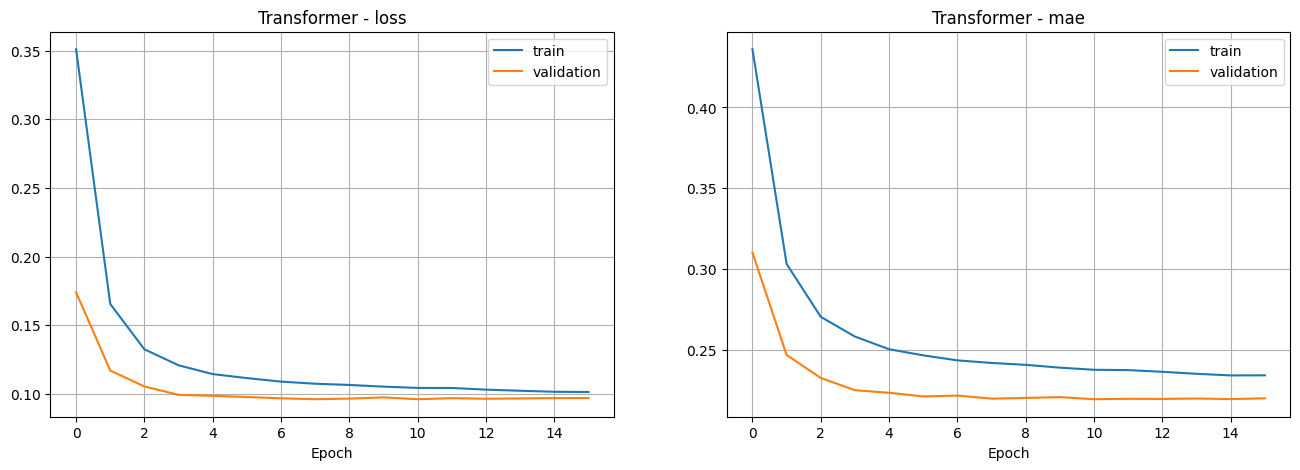

Transformer: mean RMSE = 1.174 m/s, mean skill = -0.7%


,RMSE [m/s],MAE [m/s],Skill vs. persistence
Horizon [min],,,
10,0.795,0.551,-0.127
20,0.995,0.704,-0.026
30,1.160,0.825,-0.003
40,1.273,0.913,0.019
50,1.372,0.991,0.038
60,1.451,1.052,0.058


In [70]:
model_transformer.compile(loss='mse', optimizer=keras.optimizers.Adam(learning_rate=5e-4), metrics=['mae'])

history = model_transformer.fit(train_X, train_Y,
                                epochs=EPOCHS,
                                batch_size=BATCH_SIZE,
                                validation_data=(validation_X, validation_Y),
                                callbacks=[es],
                                verbose=2)

plot_history(history, 'Transformer')
evaluate_forecast(model_transformer, 'Transformer')

### Is the Transformer the winner?

Not necessarily – and that is an important lesson. Transformers shine with **long sequences** and **lots of data** (they were built for language, trained on billions of tokens). For a 36-step window and ~30k training samples, the recurrent models' built-in notion of order (their *inductive bias*) is often worth more than the Transformer's flexibility. Large time-series Transformers also typically need tricks such as learning-rate warm-up, and much more tuning.

Pick the model that fits your problem and data, not the one that is most fashionable.

# Part 9 – Compare all models

In [71]:
summary = pd.DataFrame({
    name: {'Mean RMSE [m/s]': r['rmse'].mean(),
           'Mean MAE [m/s]': r['mae'].mean(),
           'RMSE @ 10 min': r['rmse'][0],
           'RMSE @ 60 min': r['rmse'][-1],
           'Mean skill vs. persistence': (1 - r['rmse'] / results['Persistence']['rmse']).mean()}
    for name, r in results.items()}).T

summary.round(3)

,Mean RMSE [m/s],Mean MAE [m/s],RMSE @ 10 min,RMSE @ 60 min,Mean skill vs. persistence
Persistence,1.183,0.857,0.706,1.540,0.000
LSTM,1.127,0.824,0.692,1.435,0.043
GRU,1.123,0.821,0.686,1.430,0.048
GRU + Attention,1.124,0.821,0.698,1.425,0.045
GRU (tuned),1.121,0.823,0.691,1.426,0.048
Transformer,1.174,0.839,0.795,1.451,-0.007


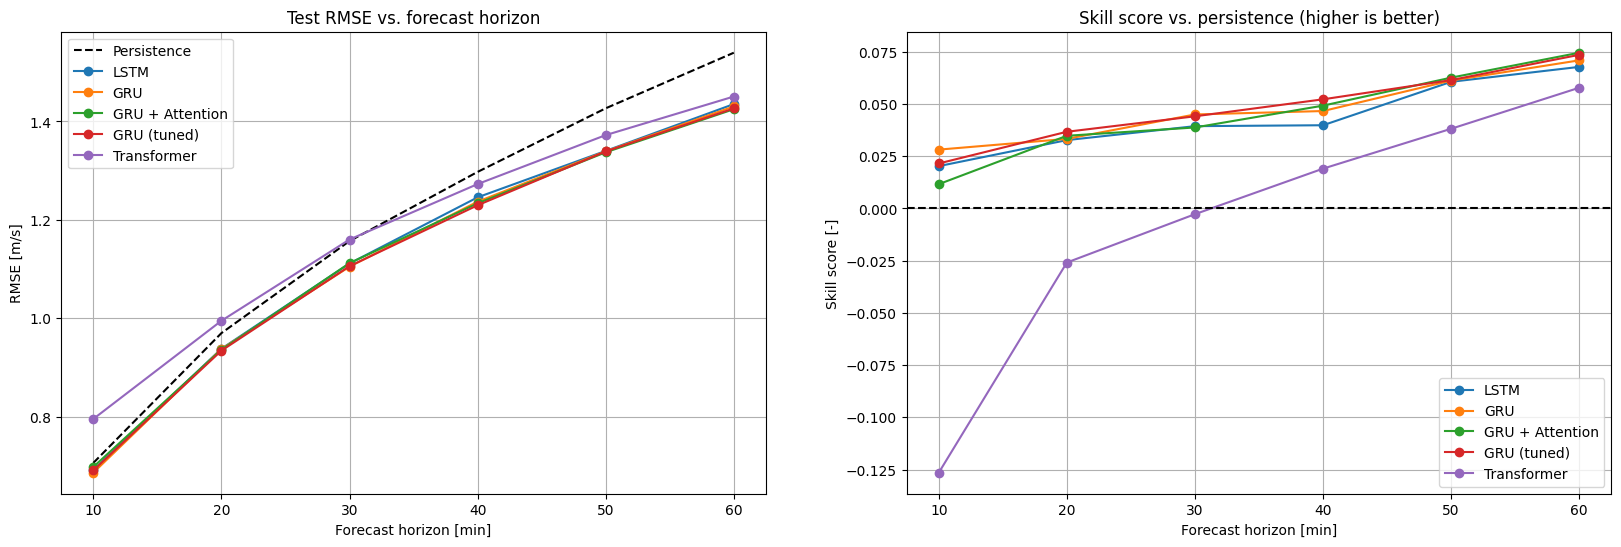

In [72]:
fig, axes = plt.subplots(1, 2, figsize=(20, 6))

for name, r in results.items():
    style = 'k--' if name == 'Persistence' else '-o'
    axes[0].plot(horizon_minutes, r['rmse'], style, label=name)
    if name != 'Persistence':
        axes[1].plot(horizon_minutes, 1 - r['rmse'] / results['Persistence']['rmse'], '-o', label=name)

axes[0].set_title('Test RMSE vs. forecast horizon')
axes[0].set_ylabel('RMSE [m/s]')
axes[1].axhline(0, color='k', ls='--')
axes[1].set_title('Skill score vs. persistence (higher is better)')
axes[1].set_ylabel('Skill score [-]')
for ax in axes:
    ax.set_xlabel('Forecast horizon [min]')
    ax.legend()
    ax.grid()
plt.show()

### Look at actual forecasts, not only at numbers

Metrics average over thousands of forecasts. Plotting a few of them shows *how* the models behave – e.g. whether they just repeat the last value, or catch ramps.

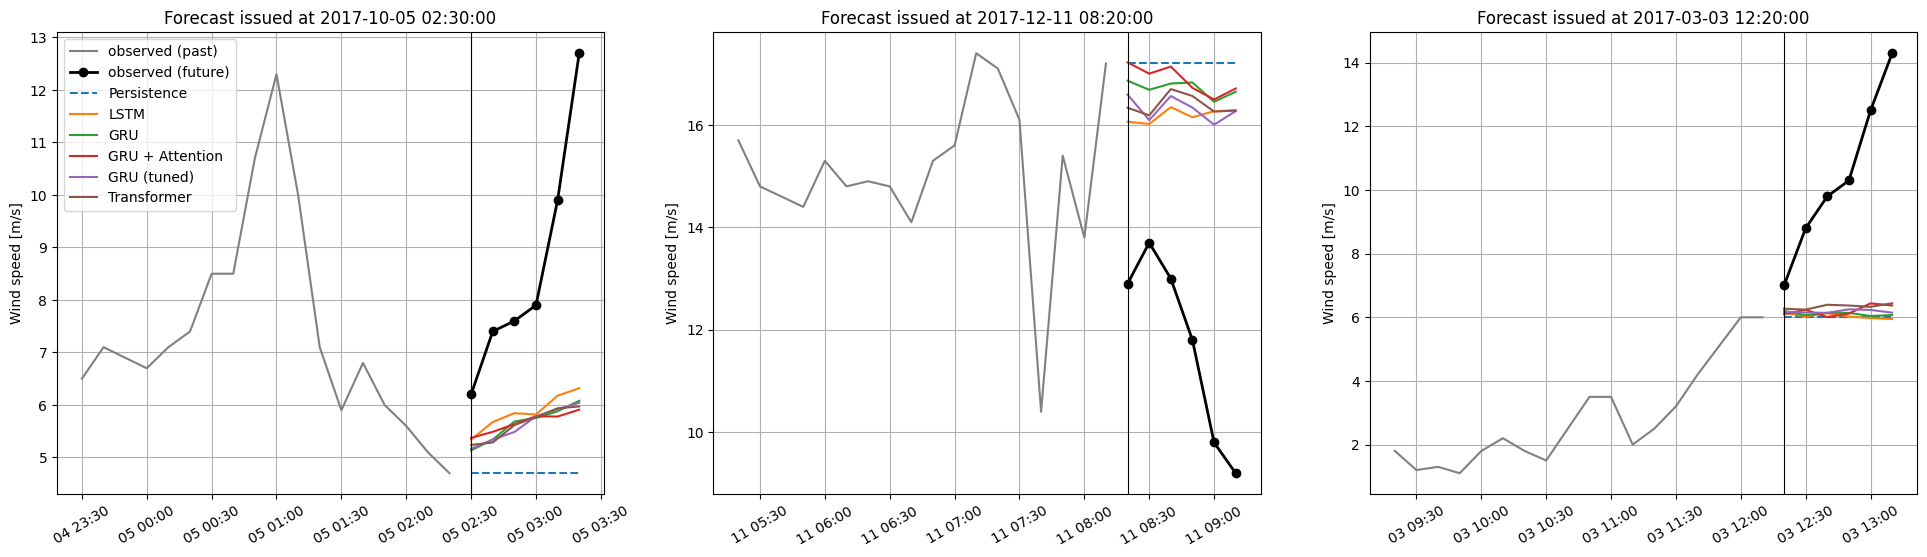

In [73]:
# pick the test forecasts with the largest change in wind speed within the hour (ramps are the hard cases)
ramp = np.abs(test_Y_ms[:, -1] - test_persistence[:, 0])
sample_idx = np.argsort(ramp)[-3:]

fig, axes = plt.subplots(1, 3, figsize=(24, 6))
for ax, idx in zip(axes, sample_idx):
    t0 = test_times[idx]
    history_ws = data['target'].loc[t0 - pd.Timedelta('3h'): t0 - pd.Timedelta(sampling_rate)]
    future_times = pd.date_range(t0, periods=n_out, freq=sampling_rate)

    ax.plot(history_ws, color='grey', label='observed (past)')
    ax.plot(future_times, test_Y_ms[idx], 'k-o', lw=2, label='observed (future)')
    for name, r in results.items():
        ax.plot(future_times, r['pred'][idx], '--' if name == 'Persistence' else '-', label=name)
    ax.axvline(t0, color='k', lw=0.8)
    ax.set_title(f'Forecast issued at {t0}')
    ax.set_ylabel('Wind speed [m/s]')
    ax.tick_params(axis='x', rotation=30)
    ax.grid()
axes[0].legend()
plt.show()

Discuss:
* Which model would you choose, and is the difference between the models **meaningful**? (Hint: train the same model twice with a different seed and see how much the RMSE changes.)
* How does the skill evolve with the horizon? Why is it so hard to beat persistence at 10 minutes?
* A skill of a few percent may look disappointing. Is it? Think about what 1-2% lower wind speed error means for the *power* error, given the $U^3$ relation.
* In the ramp examples – do the models predict the ramp, or do they follow it one step late?

# Try it yourself

1. **More inputs.** Add the 1-hour *trailing* mean wind speed as a feature. Then try the wind speed of the neighbouring turbines (T06, T07, T11 are in the same file) – the wind reaching them first may tell T01 what's coming.
2. **Longer horizon.** Change `n_out` to 36 (6 hours). How does the skill vs. persistence change with the horizon? (Hint: a 6-hour look-back may no longer be enough.)
3. **Tune another model.** Write a `HyperModel` for the attention model or the Transformer (`d_model`, `num_heads`, `n_blocks`, dropout). Is it worth the extra computation?
4. **Robustness.** Train each model with 3 different seeds and report mean ± standard deviation of the RMSE. Does the ranking still hold?

## Additional info on time series forecasting – things to watch out for!

### 1. Data leakage – the silent killer

**What to watch out for:** Any information from the future that ends up in the inputs makes the test results look great and the real forecast useless. Typical sources:

- shuffling **before** the train/validation/test split
- fitting the scaler on the full dataset instead of the training set only
- **centred** rolling windows or filters
- **interpolating** gaps with values that lie after the forecast origin
- features that are only known afterwards (e.g. a daily mean used at 08:00)

**Key tip:** For every input, ask: *"Would I have this exact value at the moment I issue the forecast?"*

(Shuffling the *sequences* during `model.fit` is fine: each sequence is self-contained once it is built.)

---

### 2. Direct vs. recursive multi-step forecasting

**Direct** (what we did): one output neuron per horizon step. Simple, and errors don't accumulate.

**Recursive**: predict one step, feed the prediction back in as an input, predict the next step, and so on.
```python
window = last_observed_window.copy()          # (1, n_lag, features)
forecast = []
for k in range(n_out):
    y_next = model.predict(window, verbose=0)[0, 0]
    forecast.append(y_next)
    new_step = build_features(y_next, time=t0 + k*dt)   # you need ALL features of the next step!
    window = np.concatenate([window[:, 1:, :], new_step[None, None, :]], axis=1)
```
Flexible for any horizon, but errors **accumulate**, and you need to know (or forecast) *every* input feature of the future steps.

**Sequence-to-sequence** (encoder-decoder) models sit in between: an encoder reads the past, a decoder generates the future step by step – the original setting in which attention was invented.

---

### 3. Masking pitfalls

- `Masking` only masks a step when **all** features equal `mask_value` – pad the whole time step.
- Choose a `pad_value` that cannot occur in your scaled data.
- Not every layer supports masks. Recurrent layers, `Dropout` and the attention layers do. In a Transformer, pass the mask explicitly, as we did.
- Masking is not imputation: a sequence that is mostly padding still gives a poor forecast – filter those out.

---

### 4. Non-stationary data

**What to watch out for:** Statistical properties (mean, variance) that change over time – seasons, trends, sensor drift. Wind speed is roughly stationary over a few hours, but its distribution changes with the seasons (look at the split histograms!).

**Solutions:**
- **Differencing** – forecast the *change* $\Delta U = U_t - U_{t-1}$ instead of $U$ itself
  ```python
  df['diff_1'] = df['value'].diff()
  ```
- **Seasonal features** – like our $\sin$/$\cos$ time of day (or day of year for multi-year data)
- **Train on several years** of data, so that every season is represented

---

### 5. Inverse transform the output

**What to watch out for:** Your model predicts in the **scaled (and possibly differenced) space**. Always transform back before computing metrics or plotting – and reverse the steps in the opposite order to how you applied them.

```python
pred_ms = y_scaler.inverse_transform(pred_scaled.reshape(-1, 1)).reshape(pred_scaled.shape)

# if you forecast differences: integrate back from the last observation
pred_ms = last_observed_value + np.cumsum(pred_diff_ms, axis=1)
```

---

### 6. Beyond today's models

For more advanced time-series deep learning, have a look at the **Temporal Fusion Transformer** (combines LSTMs, attention and interpretable variable selection), **N-BEATS** (a pure fully-connected architecture that performs surprisingly well), and **PatchTST** (a Transformer that groups time steps into patches). Ready-made Transformer blocks are also available in the `keras_hub` package.